<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QGAN_HardwareWatermark_Ghosh2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hardware-noise watermarking of a quantum GAN: "Guardians of the Quantum GAN" step by step

**Paper.** Archisman Ghosh, Debarshi Kundu, Avimita Chatterjee, Swaroop Ghosh, *Guardians of the Quantum GAN*,
26th International Symposium on Quality Electronic Design (ISQED) 2025.
DOI: [10.1109/ISQED65160.2025.11014340](https://doi.org/10.1109/isqed65160.2025.11014340),
arXiv: [2404.16156](https://arxiv.org/abs/2404.16156).

**Topic: model theft / model extraction.** A quantum GAN (qGAN) is expensive to design and train on cloud quantum
hardware. If the trained circuit is later sent to an *untrusted* quantum cloud for inference, the provider (or a rogue
tenant) can copy it and sell the copy. The paper proposes a *watermark that costs nothing to embed*: the noise of the
quantum computer used for **training** leaves a fingerprint in the learned rotation angles, and therefore in the
generated images. The owner trains a small image classifier that reads this fingerprint back
("which hardware was this qGAN trained on?") and uses it as proof of ownership of a suspected copy.

**What this notebook does.**
1. Loads the 8x8 handwritten-digit images the paper uses (UCI *Optical Recognition of Handwritten Digits*).
2. Builds *noise models of 13 IBM devices* from the calibration snapshots shipped with Qiskit (the real
   machines are replaced by density-matrix simulation of these noise models, exactly the "fake backend" idea of the paper).
3. Implements the **Patch qGAN** (4 sub-generators x 5 qubits = 100 angles, classical discriminator) in a
   noisy simulator that is checked against PennyLane (`default.mixed`) and Qiskit Aer.
4. Trains the qGAN on single devices and on *sequences* of two devices, for several random seeds.
5. Generates images while running the trained generator on *other* devices ("stolen model, different hardware").
6. Trains the 3-convolution CNN of the paper's Table III to read the training hardware from the images,
   evaluates it in the paper's way **and** on independent re-trainings, and checks the ownership threshold `M`,
   unknown hardware, hardware *order*, FID-style quality overhead and watermark *tampering*.
7. Prints the paper's numbers next to ours with an explicit verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default) takes about 15-20 minutes
on an idle laptop-class CPU (several times longer on a busy or 2-core machine); `FAST_MODE = False` follows the paper's 500 training steps, 3+2 seeds and 100 images per run and takes several hours. No GPU, no
IBM account and no data download are needed (the digits ship with scikit-learn; real IBM hardware is **not** used).

**What you get at the end.** Every figure type of the paper (parameter drift, image grid, FID-style bars, classifier
curves, probability bars for known/unknown hardware, tamper curve) re-drawn from our own runs, the paper-vs-notebook
table, and an honest discussion of what the watermark does and does not show.

## The paper in one page

| Item | What the paper says |
|---|---|
| Problem | Protect the IP of a trained qGAN against theft by an untrusted quantum cloud vendor |
| Idea | Training on noisy hardware embeds that hardware's noise signature in the learned angles ("natural watermark") |
| Model | Patch qGAN of Huang et al. 2021: 4 sub-generators, each a 5-qubit PQC (4 data qubits + 1 ancilla), D layers of `RY` + `CZ`; classical discriminator 64-16-1 (PyTorch) |
| Generator details | Latent `z ~ U[0, pi/2)^5` fed by `RY(z)`; `D` x (`RY(theta)` layer, `CZ` ladder); measure; post-select ancilla = 0; each patch divided by its maximum; 4 patches = 8x8 image; **100 angles** in total (so `D = 5`) |
| Training | Digits data (UCI optdigits, 8x8, label 0 as in Fig. 6), PennyLane + PyTorch, **500 epochs**, SGD for both nets, BCE loss, learning rates 0.2 (generator) / 0.01 (discriminator) |
| Hardware | 10 IBM fake backends (Table IV): Athens, Bogota, Burlington (5q), Jakarta, Nairobi, Lagos (7q), Cairo, Cambridge, Kolkata (27q), Washington (127q); noise = readout, Pauli-X, thermal-relaxation |
| Watermark extraction | CNN (Table III), 8x8 images up-scaled to 150x150, 3 conv layers (32/64/128), Dense 512, softmax over the hardware labels; Adam, categorical cross-entropy, batch 64, 15 epochs |
| Single hardware | Train on each of the 10 devices, infer on all 10, 100 images each: 10 labels. Claim: **100 %** extraction accuracy, ownership threshold **M = 0.9999** |
| Multiple hardware | Train on an ordered pair of {Athens, Jakarta, Kolkata, Washington}: 12 pairs + 4 singles = 16 labels, 16,000 images. Claim: **about 90 %** accuracy, **M = 0.9**; sequence *order* matters (M = 0.999 for the 6-label order test) |
| Unknown hardware | Casablanca, Almaden, Essex were not in the suite; their images must get a probability **below M** |
| Quality | FID of generated vs real images is low on all devices (Fig. 5); training on a pair of devices raises FID by **about 7.4 %** on average, **about 18 %** for Athens-then-Jakarta, **about 0 %** for Jakarta-then-Athens (Fig. 9) |
| Tampering | Re-training the stolen model on other hardware for up to 100 epochs keeps the prediction probability above M (Fig. 10) |
| Uniqueness | Collision probability 0.1 for one device, "about 13 times" lower for a sequence of two, about 1e-5 for 5 of 15 devices |

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Quantum hardware | Qiskit fake IBM backends simulated through the PennyLane-Qiskit plugin | Own density-matrix simulator whose noise (readout, `sx`/`cx` error, T1/T2 thermal relaxation) is derived from the same Qiskit fake-backend calibration data; verified against PennyLane `default.mixed` and **Qiskit Aer** (`# CHOICE`) |
| Noise per device | "mean of readout, Pauli-X and thermal relaxation over all qubits" | **Median** over qubits/edges (a mean is spoiled by one bad qubit), `RY` = 2 `sx` pulses, `CZ` = H-CX-H; "TR" of Table IV cannot be recomputed (not defined in the paper) (`# CHOICE`) |
| Qubit count / coupling map of the device | influences transpilation | **Not modelled**: the 5-qubit sub-generator uses the device-median noise; `n_qubits` plays no role (`# CHOICE`) |
| Calibration snapshots | those of 2024 | Those shipped with `qiskit-ibm-runtime==0.50.0`; they match Table IV for some devices only (compared below) |
| Training steps | 500 epochs | 500 (`FAST_MODE=False`), 250 (`FAST_MODE=True`; with 100 steps the hardware signature was too weak for the CNN to learn in 8 epochs) |
| Mini-batch of the qGAN | not stated | 2 images per step (`# CHOICE`) |
| Epoch split for two devices | "a few epochs, then migrate" | Half of the epochs on each device (`# CHOICE`) |
| Seeds | not stated | Each classifier-training set contains several independent qGAN trainings (seeds); test sets use *unseen* seeds (`# CHOICE`) |
| Inference | shots on the Aer simulator | Exact output probabilities of the noisy circuit (no shot noise), random latent vectors (`# CHOICE`) |
| Images for the CNN | 8x8 up-scaled to 150x150 | bilinear up-scaling to `IMG_SIZE` (32 here; 150 is possible but about 20x slower) (`# CHOICE`) |
| CNN framework | TensorFlow | Same architecture in PyTorch (`# CHOICE`) |
| FID | Inception FID (not described how 8x8 digits are fed) | Frechet distance on the 16-d hidden layer of a small digit classifier ("FDD"); absolute numbers are **not comparable**, relative changes are (`# CHOICE`) |
| Threshold M | mean predicted probability of the correct hardware on known test images | Same definition |
| Tampering | "train on unknown hardware for a few epochs" | Fine-tune on an unknown device (Casablanca) with a fresh discriminator (`# CHOICE`) |

In [1]:
# Installs are pinned to the versions this notebook was tested with. Colab already ships numpy/pandas/scikit-learn/matplotlib/torch.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
if IN_COLAB or not all(_have(m) for m in ["qiskit", "qiskit_aer", "qiskit_ibm_runtime", "pennylane", "torch"]):
    !pip -q install "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" "pennylane==0.45.1" pylatexenc
    # If Colab asks for a runtime restart after this cell, restart and run all again.

In [2]:
# ---------------------------------------------------------------- configuration: every tunable constant lives here
import os, time
NB_T0 = time.time()
SEED = 42
FAST_MODE = True                 # True: ~10 min demo; False: paper budgets (about an hour on a laptop CPU)
IBM_TOKEN = ""                   # unused: the notebook never talks to IBM hardware (hardware is replaced by noise models)
DATA_SOURCE = "sklearn"          # "sklearn": bundled copy of the UCI test split (1797 images) | "uci": download optdigits via ucimlrepo
DATA_DIR = "qgan_watermark_data"

EPOCHS = 250 if FAST_MODE else 500                 # qGAN training steps (paper: 500)
BATCH = 2                                          # CHOICE: qGAN mini-batch
LR_G, LR_D = 0.2, 0.01                             # paper values
TRAIN_SEEDS = [0, 1] if FAST_MODE else [0, 1, 2]   # independent qGAN trainings that build the classifier's training data
TEST_SEEDS = [100] if FAST_MODE else [100, 101]    # unseen re-trainings used as test data
N_IMG = 50 if FAST_MODE else 100                   # images per (trained model, inference device); paper: 100
IMG_SIZE = 32                                      # CNN input side (paper: 150, see Table III)
CLS_EPOCHS = 10 if FAST_MODE else 15                # paper: 15
CLS_BATCH = 64                                     # paper: 64
TAMPER_EPOCHS = 40 if FAST_MODE else 100           # paper Fig. 10: up to 100
TAMPER_EVERY = 10
N_THREADS = 2                                      # CHOICE: small thread count is faster on shared / small CPUs

# the paper's hardware suite (Table IV) and the devices that were NOT in the suite
HW_SUITE = ["Athens", "Bogota", "Burlington", "Jakarta", "Nairobi", "Lagos", "Cairo", "Cambridge", "Kolkata", "Washington"]
HW_MULTI = ["Athens", "Jakarta", "Kolkata", "Washington"]          # 4 devices -> 12 ordered pairs
HW_UNKNOWN = ["Casablanca", "Almaden", "Essex"]
KNOWN_SINGLE_TEST = ["Washington", "Cambridge"]                    # paper Fig. 8.1 known labels

if os.environ.get("QGAN_TINY") == "1":             # debug switch used by the author to smoke-test the code in seconds
    EPOCHS, N_IMG, TRAIN_SEEDS, TEST_SEEDS, CLS_EPOCHS, TAMPER_EPOCHS, TAMPER_EVERY = 6, 6, [0, 1], [100], 1, 4, 2
print(f"FAST_MODE={FAST_MODE} EPOCHS={EPOCHS} TRAIN_SEEDS={TRAIN_SEEDS} TEST_SEEDS={TEST_SEEDS} N_IMG={N_IMG} IMG_SIZE={IMG_SIZE}")

FAST_MODE=True EPOCHS=250 TRAIN_SEEDS=[0, 1] TEST_SEEDS=[100] N_IMG=50 IMG_SIZE=32


In [3]:
import copy, time, warnings, itertools, math
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import linalg
import pennylane as qml
import qiskit, qiskit_aer
from qiskit.quantum_info import Kraus, SuperOp
from qiskit_aer.noise import depolarizing_error, thermal_relaxation_error
from qiskit_ibm_runtime import fake_provider
import sklearn
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings("ignore")

np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(max(1, min(N_THREADS, os.cpu_count() or 1)))
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| sklearn", sklearn.__version__)

numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | sklearn 1.9.1


## 1. Data: the handwritten digits (UCI optdigits)

The paper trains the qGAN on the *Optical Recognition of Handwritten Digits* data set (UCI, 8x8 pixels, 16 grey levels) and
shows digit **0** in Fig. 6. scikit-learn ships the 1797-image test split of exactly this data set offline; set
`DATA_SOURCE = "uci"` to download the full 5620-image set from the UCI repository instead. Only the zeros are used to train
the qGAN (that is also what the PennyLane patch-GAN tutorial, on which the paper builds, does).

In [4]:
os.makedirs(DATA_DIR, exist_ok=True)
def load_data():
    if DATA_SOURCE == "uci":
        try:
            from ucimlrepo import fetch_ucirepo
            ds = fetch_ucirepo(id=80)                         # Optical Recognition of Handwritten Digits
            return ds.data.features.values.astype(float), ds.data.targets.values.ravel().astype(int), "UCI (ucimlrepo id 80)"
        except Exception as e:
            print("UCI download failed, falling back to the bundled copy:", repr(e)[:100])
    X, y = load_digits(return_X_y=True)
    return X.astype(float), y.astype(int), "scikit-learn bundled copy of the UCI optdigits test split"
X_all, y_all, SRC = load_data()
real = torch.tensor(X_all[y_all == 0] / 16.0)                 # label-0 images scaled to [0,1], shape (n0, 64)
print("source:", SRC, "| all images:", X_all.shape, "| zeros used for qGAN training:", tuple(real.shape))

source: scikit-learn bundled copy of the UCI optdigits test split | all images: (1797, 64) | zeros used for qGAN training: (178, 64)


## Dataset Exploration and Visualisation

shape: (1797, 64) | features: 64 e.g. ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3'] ... ['pixel_7_6', 'pixel_7_7']
grey levels: 0 to 16 | original labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


,0,1,2,3,4,5,6,7,8,9
images,178,182,177,183,181,182,181,179,174,180


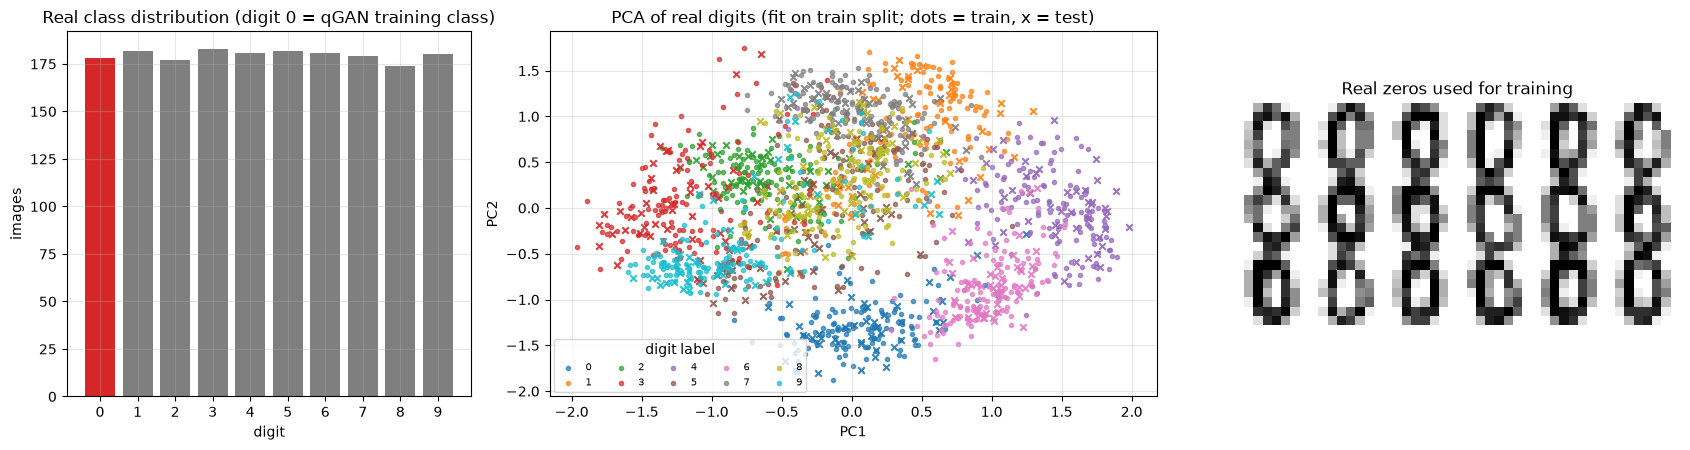

In [5]:
# --- shape, feature names, original labels, class counts
feature_names = [f"pixel_{r}_{c}" for r in range(8) for c in range(8)]
print("shape:", X_all.shape, "| features:", len(feature_names), "e.g.", feature_names[:4], "...", feature_names[-2:])
print("grey levels:", int(X_all.min()), "to", int(X_all.max()), "| original labels:", sorted(np.unique(y_all).tolist()))
counts = pd.Series(y_all).value_counts().sort_index()
display(counts.rename("images").to_frame().T)

# stratified split: PCA is fitted on the training split only (the qGAN itself only needs the zeros)
Xtr_d, Xte_d, ytr_d, yte_d = train_test_split(X_all, y_all, test_size=0.25, stratify=y_all, random_state=SEED)
pca2 = PCA(n_components=2, random_state=SEED).fit(Xtr_d / 16.0)
Ptr, Pte = pca2.transform(Xtr_d / 16.0), pca2.transform(Xte_d / 16.0)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.5, 1.1]})
colors = ["#d62728" if k == 0 else "#7f7f7f" for k in counts.index]
ax[0].bar(counts.index.astype(str), counts.values, color=colors)
ax[0].set_title("Real class distribution (digit 0 = qGAN training class)"); ax[0].set_xlabel("digit"); ax[0].set_ylabel("images")
cmap = plt.get_cmap("tab10")
for k in range(10):
    m = ytr_d == k
    ax[1].scatter(Ptr[m, 0], Ptr[m, 1], s=9, color=cmap(k), alpha=0.7, label=str(k))
    m = yte_d == k
    ax[1].scatter(Pte[m, 0], Pte[m, 1], s=22, marker="x", color=cmap(k), alpha=0.9)
ax[1].set_title("PCA of real digits (fit on train split; dots = train, x = test)"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
ax[1].legend(ncol=5, fontsize=7, title="digit label")
grid = np.concatenate([np.concatenate([real[i * 6 + j].reshape(8, 8).numpy() for j in range(6)], axis=1) for i in range(3)], axis=0)
ax[2].imshow(grid, cmap="gray_r"); ax[2].set_title("Real zeros used for training"); ax[2].axis("off")
plt.tight_layout(); plt.show()

The scatter shows the *real* images in the first two principal components, coloured by their true digit; zeros (label 0) form a
well separated cluster, which is why the paper can use them as an easy target for a very small generator. The qGAN is
**not** angle-encoded (its input is a random latent vector), so there is no `[0, pi]` angle scatter for the data; the
labelled projection of the *generated* images (coloured by training hardware, the actual classification target of the
paper) is drawn in section 6.

## 2. Noise models of the IBM devices

Qiskit's *fake backends* are frozen snapshots of the calibration data of real IBM machines. The paper trains and runs the
qGAN with noise models derived from them. We extract, per device, the median readout error, the `sx` (single-pulse) error, the
two-qubit error, T1/T2 and the gate durations, and compare the readout and Pauli-X numbers with the paper's **Table IV**.

In [6]:
# ---------------------------------------------------------------- noise models from IBM fake-backend calibrations
def _med(v):
    v = [x for x in v if x is not None and not np.isnan(x)]
    return float(np.median(v)) if v else float("nan")

def spec_from_backend(fake):
    """Median calibration numbers of a fake IBM backend (CHOICE: median over qubits/edges instead of the mean,
    because a single bad qubit (e.g. on Lagos) ruins a mean)."""
    t = fake.target
    nq = fake.num_qubits
    ops = t.operation_names
    ro = _med([t["measure"][(q,)].error for q in range(nq)])
    ro_mean = float(np.mean([t["measure"][(q,)].error for q in range(nq)]))
    g1 = "sx" if "sx" in ops else "u2"
    e_pulse = _med([t[g1][(q,)].error for q in range(nq)])
    e_pulse_mean = float(np.mean([t[g1][(q,)].error for q in range(nq)]))
    d_pulse = _med([t[g1][(q,)].duration for q in range(nq)])
    g2 = [k for k in ops if k in ("cx", "ecr", "cz")][0]
    e2 = _med([p.error for p in t[g2].values()])
    d2 = _med([p.duration for p in t[g2].values()])
    T1 = _med([t.qubit_properties[q].t1 for q in range(nq)])
    T2 = _med([t.qubit_properties[q].t2 for q in range(nq)])
    return dict(n_qubits=nq, readout=ro, readout_mean=ro_mean, sx_error=e_pulse, sx_error_mean=e_pulse_mean,
                cx_error=e2, T1=T1, T2=min(T2, 2 * T1), t_pulse=d_pulse, t_2q=d2)

def _avg_infid(kraus_list, d):
    fe = sum(abs(np.trace(K)) ** 2 for K in kraus_list) / d ** 2
    return 1 - (d * fe + 1) / (d + 1)

def build_noise(spec, scale=1.0):
    """Calibration numbers -> Kraus operators. One RY = 2 sqrt(X) pulses, one CZ = H CX H (CHOICE).
    Gate error = depolarising part + thermal-relaxation part (T1, T2, gate time); readout = symmetric bit flip."""
    T1, T2 = spec["T1"], spec["T2"]
    t_ry = 2 * spec["t_pulse"]
    t_cz = spec["t_2q"] + 2 * spec["t_pulse"]
    e_ry = scale * 2 * spec["sx_error"]
    e_cz = scale * spec["cx_error"]
    th_ry = thermal_relaxation_error(T1, T2, t_ry)
    th_cz = thermal_relaxation_error(T1, T2, t_cz)
    k_th_ry = Kraus(th_ry.to_quantumchannel()).data
    k_th_cz = Kraus(th_cz.to_quantumchannel()).data
    lam1 = max(0.0, 2 * (e_ry - _avg_infid(k_th_ry, 2)))
    k_cz2 = [np.kron(a, b) for a in k_th_cz for b in k_th_cz]
    lam2 = max(0.0, (4 / 3) * (e_cz - _avg_infid(k_cz2, 4)))
    ch = SuperOp(depolarizing_error(lam1, 1).to_quantumchannel()).compose(SuperOp(th_ry.to_quantumchannel()))
    return dict(k_ry=[np.array(k) for k in Kraus(ch).data], k_cz=[np.array(k) for k in k_th_cz], lam1=lam1, lam2=lam2,
                p_ro=min(0.5, scale * spec["readout"]), spec=spec, scale=scale, e_ry=e_ry, e_cz=e_cz)

In [7]:
PAPER_T4 = {  # paper Table IV: qubits, readout, Pauli-X, TR
    "Athens": (5, .017, 4.82e-4, .035), "Bogota": (5, .038, 4.00e-4, .019), "Burlington": (5, .035, 7.02e-4, .027),
    "Jakarta": (7, .025, 3.49e-4, .041), "Nairobi": (7, .027, 3.06e-4, .021), "Lagos": (7, .009, 2.58e-4, .023),
    "Cairo": (27, .016, 3.07e-4, .024), "Cambridge": (27, .107, 9.59e-4, .039), "Kolkata": (27, .012, 3.20e-4, .022),
    "Washington": (127, .049, 2.00e-4, .030)}
SPEC = {n: spec_from_backend(getattr(fake_provider, f"Fake{n}V2")()) for n in HW_SUITE + HW_UNKNOWN}
NOISE = {n: build_noise(s) for n, s in SPEC.items()}
rows = []
for n, s in SPEC.items():
    p = PAPER_T4.get(n)
    rows.append(dict(device=n, qubits=s["n_qubits"], paper_qubits=p[0] if p else None,
                     readout_mean=round(s["readout_mean"], 4), readout_median=round(s["readout"], 4), paper_readout=p[1] if p else None,
                     sx_err_mean=s["sx_error_mean"], paper_pauliX=p[2] if p else None,
                     cx_err_median=round(s["cx_error"], 4), T1_us=round(s["T1"] * 1e6, 1), T2_us=round(s["T2"] * 1e6, 1),
                     lam_1q=NOISE[n]["lam1"], lam_2q=round(NOISE[n]["lam2"], 4), p_readout=round(NOISE[n]["p_ro"], 4)))
T4 = pd.DataFrame(rows).set_index("device")
display(T4.style.format({"sx_err_mean": "{:.2e}", "paper_pauliX": "{:.2e}", "lam_1q": "{:.2e}"}, na_rep="-"))
ok_ro = {n: abs(T4.loc[n, "readout_mean"] - PAPER_T4[n][1]) <= 0.1 * PAPER_T4[n][1] + 1e-3 for n in HW_SUITE}
ok_x = {n: abs(T4.loc[n, "sx_err_mean"] - PAPER_T4[n][2]) <= 0.1 * PAPER_T4[n][2] for n in HW_SUITE}
print("devices whose mean readout error equals Table IV within 10 %:", [n for n, v in ok_ro.items() if v])
print("devices whose mean sx error equals Table IV within 10 %      :", [n for n, v in ok_x.items() if v])

,qubits,paper_qubits,readout_mean,readout_median,paper_readout,sx_err_mean,paper_pauliX,cx_err_median,T1_us,T2_us,lam_1q,lam_2q,p_readout
device,,,,,,,,,,,,,
Athens,5,5.000000,0.016700,0.015300,0.017000,4.82e-04,4.82e-04,0.014600,63.500000,112.200000,4.41e-04,0.012000,0.015300
Bogota,5,5.000000,0.037500,0.033900,0.038000,4.00e-04,4.00e-04,0.014800,111.100000,108.500000,3.24e-04,0.010500,0.033900
Burlington,5,5.000000,0.035000,0.032000,0.035000,7.02e-04,7.02e-04,0.016100,82.600000,93.200000,1.10e-03,0.012600,0.032000
Jakarta,7,7.000000,0.030700,0.025300,0.025000,2.76e-04,3.49e-04,0.009000,117.500000,34.200000,0.00e+00,0.000000,0.025300
Nairobi,7,7.000000,0.026600,0.022300,0.027000,4.20e-04,3.06e-04,0.007800,87.300000,106.100000,8.68e-04,0.004300,0.022300
Lagos,7,7.000000,0.203500,0.169000,0.009000,2.51e-04,2.58e-04,0.010500,105.400000,72.400000,1.32e-04,0.003400,0.169000
Cairo,27,27.000000,0.026300,0.013900,0.016000,7.63e-04,3.07e-04,0.007800,97.000000,81.400000,4.91e-04,0.005000,0.013900
Cambridge,28,27.000000,0.126800,0.065000,0.107000,1.01e-03,9.59e-04,0.030200,80.900000,51.800000,1.41e-03,0.022200,0.065000
Kolkata,27,27.000000,0.012200,0.009600,0.012000,3.22e-04,3.20e-04,0.007500,111.500000,82.700000,6.24e-06,0.002100,0.009600


devices whose mean readout error equals Table IV within 10 %: ['Athens', 'Bogota', 'Burlington', 'Nairobi', 'Kolkata']
devices whose mean sx error equals Table IV within 10 %      : ['Athens', 'Bogota', 'Burlington', 'Lagos', 'Cambridge', 'Kolkata']


Only some devices agree with Table IV: the calibration snapshots inside the current Qiskit release are not the same as the ones the
authors used (several backends were re-calibrated), and "TR" is not defined precisely enough to be recomputed. The devices still differ clearly from each other
(compare the `p_readout` and `lam_2q` columns) - that difference is the "noise signature" the watermark relies on. We therefore use the
*current* snapshots consistently for all 13 devices (10 in the suite, 3 unknown).

## 3. The simulator: three layers of the same physics

1. **Reference simulator** (`DM`, `run_circuit_reference`): applies every gate and every error channel one by one to a density matrix. Slow, transparent.
2. **Fast simulator** (`Hardware`, `probs_fast`): the noise after a layer is a *fixed* linear map of the 32x32 density matrix, so it is
   pre-multiplied once per device into one 1024x1024 matrix; only the `RY` rotations depend on the trainable angles.
3. **Patch assembly** (`patches_to_images`): post-select the ancilla on `|0>`, renormalise (this is the non-linearity of the paper), divide
   by the maximum and concatenate the four 16-pixel patches into an 8x8 image. PyTorch differentiates through all of it.

The next section proves, with assertions, that all three agree with PennyLane `default.mixed` and with Qiskit Aer.

In [8]:
# ---------------------------------------------------------------- reference simulator: gate by gate density matrix
N_Q, N_ANC, DEPTH, N_GEN = 5, 1, 5, 4            # 5 qubits (1 ancilla), D=5 layers, 4 sub-generators -> 100 parameters
PAIRS_A = [(0, 1), (2, 3)]
PAIRS_B = [(1, 2), (3, 4)]
LETTERS = "abcdefghij"

class DM:
    """Batched density matrix, tensor axes (B, r0..r4, c0..c4); qubit 0 is the leading axis (PennyLane convention).
    Slow but transparent: this is the reference every fast simulator below is asserted against."""
    def __init__(self, B, dtype=torch.complex128):
        rho = torch.zeros((B,) + (2,) * (2 * N_Q), dtype=dtype)
        rho[(slice(None),) + (0,) * (2 * N_Q)] = 1.0
        self.rho, self.B, self.dtype = rho, B, dtype

    def _idx(self, k):
        r = list(LETTERS[:N_Q]); c = list(LETTERS[N_Q:])
        r2 = r.copy(); r2[k] = "X"; c2 = c.copy(); c2[k] = "Y"
        return "".join(r), "".join(c), "".join(r2), "".join(c2), r[k], c[k]

    def unitary1(self, U, k):
        rin, cin, rout, cout, rk, ck = self._idx(k)
        t = torch.einsum(f"zX{rk},z{rin}{cin}->z{rout}{cin}", U, self.rho)
        self.rho = torch.einsum(f"zY{ck},z{rout}{cin}->z{rout}{cout}", U.conj(), t)

    def cz(self, a, b):
        idx = torch.arange(2 ** N_Q)
        bits = lambda q: (idx >> (N_Q - 1 - q)) & 1
        s = 1 - 2 * (bits(a) * bits(b))
        self.rho = self.rho * (s[:, None] * s[None, :]).to(self.dtype).reshape((2,) * (2 * N_Q))

    def kraus1(self, ks, k):
        rin, cin, rout, cout, rk, ck = self._idx(k)
        K = torch.as_tensor(np.stack(ks), dtype=self.dtype)
        t = torch.einsum(f"nX{rk},z{rin}{cin}->nz{rout}{cin}", K, self.rho)
        self.rho = torch.einsum(f"nY{ck},nz{rout}{cin}->z{rout}{cout}", K.conj(), t)

    def depol2(self, lam, a, b):
        """rho -> (1-lam) rho + lam * (I/4 on qubits a,b) x Tr_ab(rho)   (Aer's depolarizing_error(lam, 2))."""
        if lam <= 0:
            return
        r = list(LETTERS[:N_Q]); c = list(LETTERS[N_Q:])
        rin, cin = "".join(r), "".join(c)
        c_tr = c.copy(); c_tr[a] = r[a]; c_tr[b] = r[b]
        rest_r = [r[i] for i in range(N_Q) if i not in (a, b)]
        rest_c = [c[i] for i in range(N_Q) if i not in (a, b)]
        red = torch.einsum(f"z{rin}{''.join(c_tr)}->z{''.join(rest_r)}{''.join(rest_c)}", self.rho)
        eye = torch.eye(2, dtype=self.dtype)
        mixed = torch.einsum(f"z{''.join(rest_r)}{''.join(rest_c)},{r[a]}{c[a]},{r[b]}{c[b]}->z{rin}{cin}", red, eye, eye) / 4.0
        self.rho = (1 - lam) * self.rho + lam * mixed

def ry_mats(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)

def readout_matrix(p):
    R = np.array([[1 - p, p], [p, 1 - p]])
    M = np.array([[1.0]])
    for _ in range(N_Q):
        M = np.kron(M, R)
    return torch.tensor(M)

def run_circuit_reference(z, theta, noise):
    """z: (B,5) latent angles, theta: (B,25). Returns measured probabilities (B,32) incl. readout error, and the final DM."""
    dm = DM(z.shape[0])
    def ry(ang, q):
        dm.unitary1(ry_mats(ang), q)
        if noise is not None:
            dm.kraus1(noise["k_ry"], q)
    for q in range(N_Q):
        ry(z[:, q], q)
    for d in range(DEPTH):
        for q in range(N_Q):
            ry(theta[:, d * N_Q + q], q)
        for (a, b) in PAIRS_A + PAIRS_B:
            dm.cz(a, b)
            if noise is not None:
                dm.depol2(noise["lam2"], a, b)
                dm.kraus1(noise["k_cz"], a); dm.kraus1(noise["k_cz"], b)
    p = torch.diagonal(dm.rho.reshape(z.shape[0], 2 ** N_Q, 2 ** N_Q), dim1=1, dim2=2).real
    if noise is not None:
        p = p @ readout_matrix(noise["p_ro"]).T
    return p, dm

In [9]:
# ---------------------------------------------------------------- fast simulator used for training/inference
# Layer = RY layer (unitary, batched) -> single-qubit noise on 5 qubits -> CZ ladder with its noise. The two noise
# blocks are fixed linear maps on the 32x32 density matrix, pre-multiplied into ONE 1024x1024 matrix per device.
def _super1(kraus):
    return np.real(sum(np.kron(K, K.conj()) for K in kraus))

def _cz_super():
    d = np.zeros(16)
    for ra in range(2):
        for ca in range(2):
            for rb in range(2):
                for cb in range(2):
                    d[((ra * 2 + ca) * 2 + rb) * 2 + cb] = (1 - 2 * ra * rb) * (1 - 2 * ca * cb)
    return np.diag(d)

def _depol2_super(lam):
    v = np.zeros(16)
    for ra in range(2):
        for rb in range(2):
            v[((ra * 2 + ra) * 2 + rb) * 2 + rb] = 1
    return (1 - lam) * np.eye(16) + lam / 4 * np.outer(v, v)

def _to_inter(rho):     # (B,32,32) -> (B,4,4,4,4,4): axes (r_k, c_k) interleaved and merged per qubit
    B = rho.shape[0]
    return rho.reshape((B,) + (2,) * (2 * N_Q)).permute(0, 1, 6, 2, 7, 3, 8, 4, 9, 5, 10).reshape(B, 4, 4, 4, 4, 4)

def _from_inter(x):
    B = x.shape[0]
    return x.reshape((B,) + (2,) * (2 * N_Q)).permute(0, 1, 3, 5, 7, 9, 2, 4, 6, 8, 10).reshape(B, 2 ** N_Q, 2 ** N_Q)

def _apply1(x, S, q):
    B = x.shape[0]
    return torch.matmul(S, x.reshape(B * 4 ** q, 4, 4 ** (N_Q - 1 - q))).reshape(B, 4, 4, 4, 4, 4)

def _apply2(x, W, q):
    B = x.shape[0]
    return torch.matmul(W, x.reshape(B * 4 ** q, 16, 4 ** (N_Q - 2 - q))).reshape(B, 4, 4, 4, 4, 4)

def kron_ry(angles):
    """angles (B,5) -> (B,32,32) real tensor product of the five RY matrices."""
    c, s = torch.cos(angles / 2), torch.sin(angles / 2)
    U = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
    out = U[:, 0]
    for q in range(1, N_Q):
        out = torch.einsum("zij,zkl->zikjl", out, U[:, q]).reshape(out.shape[0], 2 * out.shape[1], 2 * out.shape[2])
    return out

class Hardware:
    """One device = pair of fused 1024x1024 superoperators + readout matrix. noise=None is the ideal (noise-free) device."""
    def __init__(self, name, noise, dtype=torch.float32):
        self.name, self.noise, self.dtype = name, noise, dtype
        if noise is None:
            S1, W2, R = np.eye(4), _cz_super(), None
        else:
            S_cz = _super1(noise["k_cz"])
            S1, W2 = _super1(noise["k_ry"]), np.kron(S_cz, S_cz) @ _depol2_super(noise["lam2"]) @ _cz_super()
            R = readout_matrix(noise["p_ro"])
        S1, W2 = torch.tensor(S1), torch.tensor(W2)
        n = 2 ** N_Q
        basis = torch.zeros(n * n, n, n, dtype=torch.float64)
        ii = torch.arange(n * n)
        basis[ii, ii // n, ii % n] = 1.0
        x = _to_inter(basis)
        for q in range(N_Q):
            x = _apply1(x, S1, q)
        self.N5 = _from_inter(x).reshape(n * n, n * n).to(dtype)               # noise after an RY layer
        for (a, b) in PAIRS_A + PAIRS_B:
            x = _apply2(x, W2, a)
        self.ML = _from_inter(x).reshape(n * n, n * n).to(dtype)               # RY-layer noise then CZ ladder with noise
        self.R = None if R is None else R.to(dtype)

def probs_fast(z, theta, hw):
    """z: (B,5), theta: (B,25) -> measured probabilities over the 32 basis states, shape (B,32)."""
    dt, B, n = hw.dtype, z.shape[0], 2 ** N_Q
    ket0 = torch.zeros(B, n, 1, dtype=dt); ket0[:, 0, 0] = 1
    psi = kron_ry(z.to(dt)) @ ket0
    rho = ((psi @ psi.transpose(1, 2)).reshape(B, -1) @ hw.N5).reshape(B, n, n)
    for d in range(DEPTH):
        U = kron_ry(theta[:, d * N_Q:(d + 1) * N_Q].to(dt))
        rho = U @ rho @ U.transpose(1, 2)
        rho = (rho.reshape(B, -1) @ hw.ML).reshape(B, n, n)
    p = torch.diagonal(rho, dim1=1, dim2=2)
    return p if hw.R is None else p @ hw.R.T

def patches_to_images(thetas, z, hw):
    """4 sub-generators, shared latent vector; post-select ancilla (qubit 0) = 0, normalise, divide by max (paper eq.), concatenate."""
    n = z.shape[0]
    zz = z.unsqueeze(0).expand(N_GEN, n, N_Q).reshape(N_GEN * n, N_Q)
    th = thetas.unsqueeze(1).expand(N_GEN, n, thetas.shape[1]).reshape(N_GEN * n, -1)
    g = probs_fast(zz, th, hw)[:, : 2 ** (N_Q - N_ANC)]
    g = g / g.sum(dim=1, keepdim=True)
    g = g / g.max(dim=1, keepdim=True).values
    return g.reshape(N_GEN, n, -1).permute(1, 0, 2).reshape(n, -1)

## Quantum Circuit Architecture

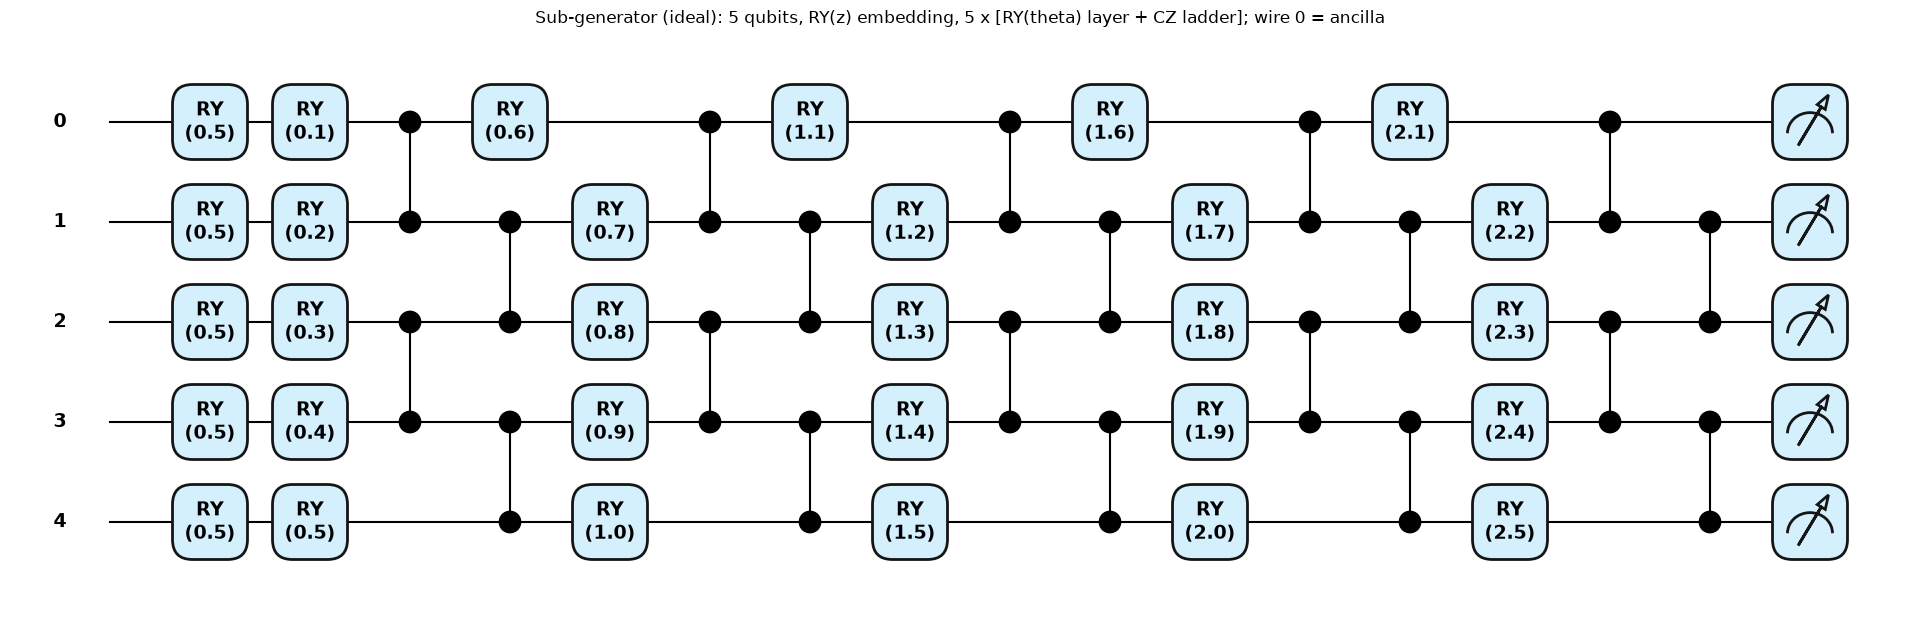

qubits per sub-generator : 5 (4 data + 1 ancilla)
sub-generators           : 4 -> patches of 16 pixels = 64-pixel (8x8) image
trainable angles         : per sub-generator 25 | total 100 (paper: 100)
gates / depth            : {'RY': 30, 'CZ': 20} | depth 16


In [10]:
# PennyLane version of ONE sub-generator (5 qubits: wire 0 = ancilla that is post-selected on |0>, wires 1-4 = data qubits)
LADDER = PAIRS_A + PAIRS_B
dev_ideal = qml.device("default.qubit", wires=N_Q)
@qml.qnode(dev_ideal)
def sub_generator(z, theta):
    for q in range(N_Q):                       # state embedding: RY(z_i)
        qml.RY(z[q], wires=q)
    for d in range(DEPTH):                     # D x (parametrised RY layer, CZ ladder)
        for q in range(N_Q):
            qml.RY(theta[d * N_Q + q], wires=q)
        for (a, b) in LADDER:
            qml.CZ(wires=[a, b])
    return qml.probs(wires=range(N_Q))

z0 = np.full(N_Q, 0.5); th0 = np.round(np.linspace(0.1, 2.5, DEPTH * N_Q), 2)
fig, ax = qml.draw_mpl(sub_generator, decimals=1, style="pennylane")(z0, th0)
fig.suptitle("Sub-generator (ideal): 5 qubits, RY(z) embedding, 5 x [RY(theta) layer + CZ ladder]; wire 0 = ancilla", y=1.02)
plt.show()
res = qml.specs(sub_generator)(z0, th0).resources
print("qubits per sub-generator :", N_Q, f"({N_Q - N_ANC} data + {N_ANC} ancilla)")
print("sub-generators           :", N_GEN, "-> patches of", 2 ** (N_Q - N_ANC), "pixels = 64-pixel (8x8) image")
print("trainable angles         : per sub-generator", DEPTH * N_Q, "| total", N_GEN * DEPTH * N_Q, "(paper: 100)")
print("gates / depth            :", dict(res.gate_types), "| depth", res.depth)

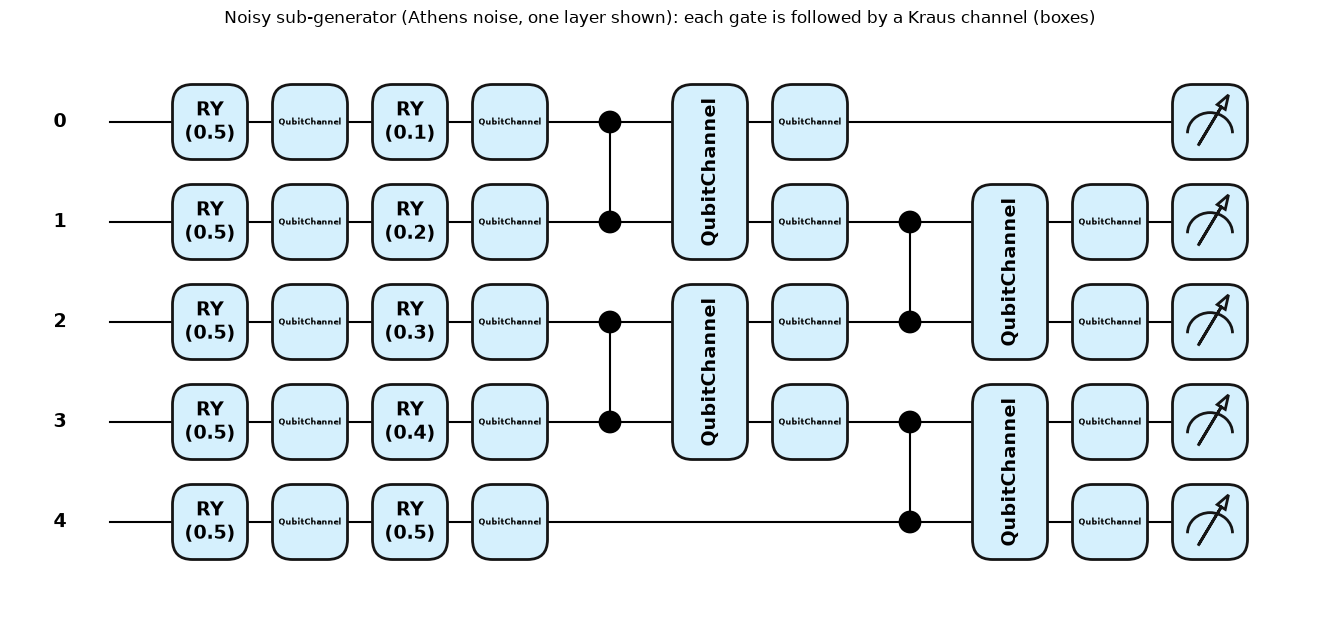

noisy circuit: qubits 5 | same 25 angles | extra per device: depolarising + thermal-relaxation channels after each gate, bit-flip readout p = 0.0153


In [11]:
# The circuit that is actually executed on a "noisy device": every gate is followed by its error channel.
# Drawn for one layer (D=1); the remaining D-1 layers repeat the same block.
P1 = [np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1, -1])]
def depol2_kraus(lam):
    """rho -> (1-lam) rho + lam I/4 x Tr(rho) written as a Pauli-Kraus channel (identical to Aer's depolarizing_error(lam, 2))."""
    return [np.sqrt((1 - lam + lam / 16) if (i == 0 and j == 0) else lam / 16) * np.kron(a, b)
            for i, a in enumerate(P1) for j, b in enumerate(P1)]

dev_mixed = qml.device("default.mixed", wires=N_Q)
@qml.qnode(dev_mixed)
def sub_generator_noisy(z, theta, noise, depth=DEPTH):
    for q in range(N_Q):
        qml.RY(z[q], wires=q); qml.QubitChannel(noise["k_ry"], wires=q)
    for d in range(depth):
        for q in range(N_Q):
            qml.RY(theta[d * N_Q + q], wires=q); qml.QubitChannel(noise["k_ry"], wires=q)
        for (a, b) in LADDER:
            qml.CZ(wires=[a, b])
            qml.QubitChannel(depol2_kraus(noise["lam2"]), wires=[a, b])
            qml.QubitChannel(noise["k_cz"], wires=a); qml.QubitChannel(noise["k_cz"], wires=b)
    return qml.probs(wires=range(N_Q))          # readout error is applied afterwards as a 32x32 confusion matrix

fig, ax = qml.draw_mpl(sub_generator_noisy, decimals=1, style="pennylane")(z0, th0, NOISE["Athens"], 1)
fig.suptitle("Noisy sub-generator (Athens noise, one layer shown): each gate is followed by a Kraus channel (boxes)", y=1.02)
plt.show()
print("noisy circuit: qubits", N_Q, "| same", DEPTH * N_Q, "angles | extra per device: depolarising + thermal-relaxation channels after each gate, bit-flip readout p =",
      round(NOISE["Athens"]["p_ro"], 4))

In [12]:
# ---- equivalence of everything that is executed (assertions; this is what makes the fast simulator trustworthy)
z_t = torch.tensor(rng.uniform(0, np.pi / 2, (3, N_Q))); th_t = torch.tensor(rng.uniform(0, 1, (3, DEPTH * N_Q)))
noise = NOISE["Cambridge"]
HW_IDEAL = Hardware("ideal", None); HW_TEST = Hardware("Cambridge", noise)
# (1) ideal: PennyLane vs gate-by-gate reference vs fast simulator
p_ref, _ = run_circuit_reference(z_t, th_t, None)
p_pl = np.stack([sub_generator(z_t[i].numpy(), th_t[i].numpy()) for i in range(3)])
p_fast = probs_fast(z_t, th_t, Hardware("ideal64", None, torch.float64)).numpy()
print("ideal  | max |PennyLane - reference| =", np.abs(p_pl - p_ref.numpy()).max(), "| max |fast - reference| =", np.abs(p_fast - p_ref.numpy()).max())
assert np.allclose(p_pl, p_ref.numpy(), atol=1e-10) and np.allclose(p_fast, p_ref.numpy(), atol=1e-10)
# (2) noisy: PennyLane default.mixed (with all channels) vs reference density matrix (before readout)
_, dm = run_circuit_reference(z_t, th_t, noise)
p_ref_noro = torch.diagonal(dm.rho.reshape(3, 32, 32), dim1=1, dim2=2).real.numpy()
p_pl_n = np.stack([sub_generator_noisy(z_t[i].numpy(), th_t[i].numpy(), noise) for i in range(3)])
print("noisy  | max |PennyLane default.mixed - reference| =", np.abs(p_pl_n - p_ref_noro).max())
assert np.allclose(p_pl_n, p_ref_noro, atol=1e-9)
# (3) noisy fast simulator (float64 build) vs reference incl. readout, and float32 build used for training
p_ref_n, _ = run_circuit_reference(z_t, th_t, noise)
p_f64 = probs_fast(z_t, th_t, Hardware("c64", noise, torch.float64)).numpy()
p_f32 = probs_fast(z_t, th_t, HW_TEST).double().numpy()
print("noisy  | max |fast64 - reference| =", np.abs(p_f64 - p_ref_n.numpy()).max(), "| max |fast32 - reference| =", np.abs(p_f32 - p_ref_n.numpy()).max())
assert np.allclose(p_f64, p_ref_n.numpy(), atol=1e-10) and np.allclose(p_f32, p_ref_n.numpy(), atol=1e-5)
# (4) Qiskit Aer density-matrix simulation with an Aer NoiseModel carrying the same channels
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, QuantumError
th_cz = QuantumError(Kraus(noise["k_cz"]))
nm = NoiseModel()
nm.add_all_qubit_quantum_error(QuantumError(Kraus(noise["k_ry"])), ["ry"])
nm.add_all_qubit_quantum_error(depolarizing_error(noise["lam2"], 2).compose(th_cz.tensor(th_cz)), ["cz"])
qc = QuantumCircuit(N_Q); Q = lambda q: N_Q - 1 - q          # Qiskit is little-endian, PennyLane/our qubit 0 is the leading one
for q in range(N_Q): qc.ry(float(z_t[0, q]), Q(q))
for d in range(DEPTH):
    for q in range(N_Q): qc.ry(float(th_t[0, d * N_Q + q]), Q(q))
    for (a, b) in LADDER: qc.cz(Q(a), Q(b))
qc.save_density_matrix()
sim = AerSimulator(method="density_matrix", noise_model=nm, seed_simulator=SEED)
rho_aer = np.array(sim.run(transpile(qc, sim, optimization_level=0)).result().data(0)["density_matrix"])
d_aer = np.abs(rho_aer - dm.rho.reshape(3, 32, 32)[0].numpy()).max()
print("noisy  | max |Aer density matrix - reference density matrix| =", d_aer)
assert d_aer < 1e-9
print("all equivalence assertions passed")

ideal  | max |PennyLane - reference| = 1.1102230246251565e-16 | max |fast - reference| = 1.3877787807814457e-16


noisy  | max |PennyLane default.mixed - reference| = 3.608224830031759e-16


noisy  | max |fast64 - reference| = 4.996003610813204e-16 | max |fast32 - reference| = 9.562771342841447e-08


noisy  | max |Aer density matrix - reference density matrix| = 1.4016565685892601e-15
all equivalence assertions passed


## 4. Training the qGAN on one device or on a sequence of devices

The qGAN is trained with plain SGD on both networks and BCE loss (learning rates 0.2 / 0.01). One *epoch* is one gradient step on a
small mini-batch (this is what the paper's "500 epochs" means in the PennyLane patch-GAN code it builds on).

* **Single-device watermark**: train all `EPOCHS` steps on device `h`.
* **Multi-device watermark**: train the first half on device `h1`, "migrate" the partially trained angles, and train the second half on `h2`
  (label `h1>h2`; the order matters).
* **Seeds**: the random initial angles, the discriminator initialisation, the real mini-batches and the latent vectors depend only on the
  seed, so two devices trained with the same seed differ *only* by their noise. Different seeds are different, independent
  trainings - they are what the classifier must generalise over if the watermark is really about the hardware.

In [13]:
# ---------------------------------------------------------------- qGAN training (SGD for both nets, BCE loss)
class Disc(nn.Module):
    """Classical discriminator: 64-64-16-1, ReLU, sigmoid (paper Section IV-A2)."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 16), nn.ReLU(), nn.Linear(16, 1), nn.Sigmoid())
    def forward(self, x):
        return self.net(x)

def init_gan(seed):
    """Generator angles ~ U[0,1) (as in the PennyLane patch-GAN tutorial the paper follows), discriminator PyTorch default."""
    g = torch.Generator().manual_seed(seed)
    thetas = torch.rand(N_GEN, DEPTH * N_Q, generator=g, dtype=torch.float64)
    torch.manual_seed(seed)
    return thetas, Disc().double()

def train_gan(state, hw, real, epochs, seed, batch=2, lrG=0.2, lrD=0.01, D_lr_scale=1.0):
    """One 'epoch' = one SGD step of D and one of G on a mini-batch (as in the paper's 500 'epochs' of the tutorial code).
    The latent/real-batch stream depends only on `seed`, so two devices trained with the same seed see identical data."""
    thetas, D = state
    D = copy.deepcopy(D)
    thetas = thetas.clone().requires_grad_(True)
    optG = torch.optim.SGD([thetas], lr=lrG)
    optD = torch.optim.SGD(D.parameters(), lr=lrD)
    bce = nn.BCELoss()
    g = torch.Generator().manual_seed(seed)
    hist, traj = [], []
    one, zero = torch.ones(batch, 1, dtype=torch.float64), torch.zeros(batch, 1, dtype=torch.float64)
    for ep in range(epochs):
        x = real[torch.randint(0, real.shape[0], (batch,), generator=g)]
        z = torch.rand(batch, N_Q, generator=g, dtype=torch.float64) * (np.pi / 2)
        fake = patches_to_images(thetas, z, hw).double()
        optD.zero_grad()
        lD = bce(D(x), one) + bce(D(fake.detach()), zero)
        lD.backward(); optD.step()
        optG.zero_grad()
        lG = bce(D(fake), one)
        lG.backward(); optG.step()
        hist.append((lD.item(), lG.item())); traj.append(thetas[0, 0].item())
    return (thetas.detach(), D), np.array(hist), np.array(traj)

@torch.no_grad()
def sample_images(thetas, hw, n, seed):
    g = torch.Generator().manual_seed(int(seed))
    z = torch.rand(n, N_Q, generator=g, dtype=torch.float64) * (np.pi / 2)
    return patches_to_images(thetas, z, hw).double().numpy()

In [14]:
HW = {n: Hardware(n, NOISE[n]) for n in NOISE}          # 13 noisy devices
HW["ideal"] = Hardware("ideal", None)                   # noise-free control
PAIRS = [(a, b) for a in HW_MULTI for b in HW_MULTI if a != b]       # 12 ordered pairs
MODELS = {}                                             # (seed, sequence tuple) -> dict(theta, traj, loss)
def train_model(seed, seq):
    key = (seed, tuple(seq))
    if key in MODELS:
        return
    state, trajs, losses = init_gan(seed), [], []
    per = EPOCHS // len(seq)
    for stage, h in enumerate(seq):
        state, hist, traj = train_gan(state, HW[h], real, per, seed * 10 + stage, batch=BATCH, lrG=LR_G, lrD=LR_D)
        trajs.append(traj); losses.append(hist)
    MODELS[key] = dict(theta=state[0], traj=np.concatenate(trajs), loss=np.concatenate(losses))

t0 = time.time()
for seed in TRAIN_SEEDS + TEST_SEEDS:
    seqs = [(h,) for h in HW_SUITE + ["ideal"]] + PAIRS
    seqs += [(h,) for h in HW_UNKNOWN]                                    # devices outside the suite: the "unknown hardware" of Fig. 8
    for seq in seqs:
        train_model(seed, seq)
    print(f"seed {seed}: {len(seqs)} qGANs trained  ({time.time() - t0:.0f} s elapsed)")
print("total qGANs:", len(MODELS), "| angles per qGAN:", MODELS[(TRAIN_SEEDS[0], ('Athens',))]["theta"].numel())

seed 0: 26 qGANs trained  (409 s elapsed)


seed 1: 26 qGANs trained  (873 s elapsed)


seed 100: 26 qGANs trained  (1240 s elapsed)
total qGANs: 78 | angles per qGAN: 100


### 4.1 Does the noise show up in the learned angles? (paper Fig. 1)

The paper plots one generator angle during training on the ideal simulator and on devices of different size and argues that
the noise "leaves a footprint". We draw the same plot for our devices. We also quantify the footprint against the thing that can
hide it: **the training randomness itself** (the same device trained with a different seed).

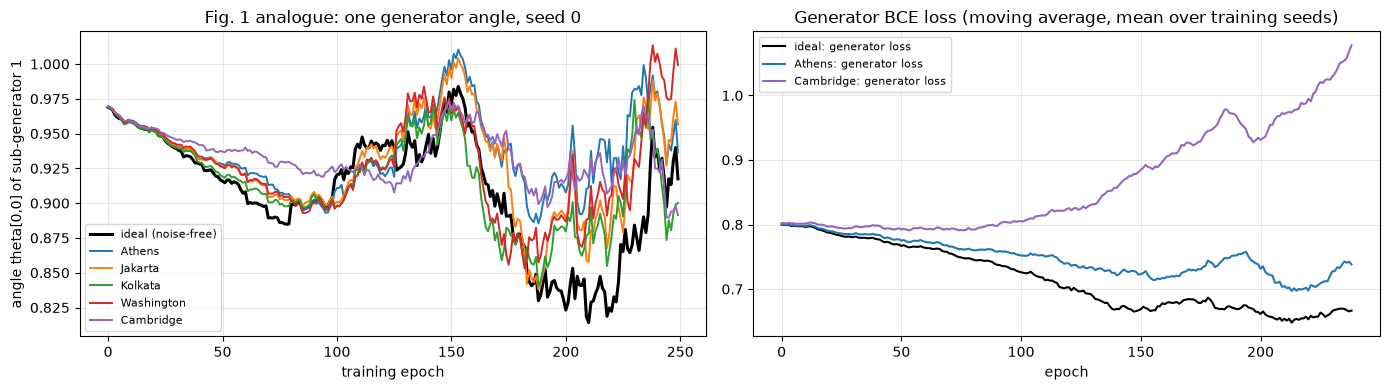

,|theta_device - theta_ideal| (same seed),|theta_seed_a - theta_seed_b| (same device)
Athens,0.1266,0.5515
Bogota,0.1586,0.5190
Burlington,0.1642,0.5208
Jakarta,0.0836,0.5542
Nairobi,0.1023,0.5209
Lagos,0.2675,0.5405
Cairo,0.0676,0.5459
Cambridge,0.2475,0.5461
Kolkata,0.0507,0.5461
Washington,0.0876,0.5533


mean noise-induced angle shift: 0.1356 rad | mean seed-induced angle difference: 0.5398 rad


In [15]:
s0 = TRAIN_SEEDS[0]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for h, c in zip(["ideal", "Athens", "Jakarta", "Kolkata", "Washington", "Cambridge"], ["k", "C0", "C1", "C2", "C3", "C4"]):
    ax[0].plot(MODELS[(s0, (h,))]["traj"], color=c, lw=1.4 if h != "ideal" else 2.2, label=h if h != "ideal" else "ideal (noise-free)")
ax[0].set_xlabel("training epoch"); ax[0].set_ylabel("angle theta[0,0] of sub-generator 1"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Fig. 1 analogue: one generator angle, seed {s0}")
for h, c in zip(["ideal", "Athens", "Cambridge"], ["k", "C0", "C4"]):
    L = np.mean([MODELS[(sd, (h,))]["loss"] for sd in TRAIN_SEEDS], axis=0)
    k = max(1, EPOCHS // 20); sm = np.convolve(L[:, 1], np.ones(k) / k, mode="valid")
    ax[1].plot(sm, color=c, label=f"{h}: generator loss")
ax[1].set_title("Generator BCE loss (moving average, mean over training seeds)"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# footprint of the noise vs footprint of the seed
drift_noise = {h: float(np.mean([np.abs(MODELS[(sd, (h,))]["theta"] - MODELS[(sd, ("ideal",))]["theta"]).mean().item() for sd in TRAIN_SEEDS])) for h in HW_SUITE}
drift_seed = {h: float(np.abs(MODELS[(TRAIN_SEEDS[0], (h,))]["theta"] - MODELS[(TRAIN_SEEDS[1], (h,))]["theta"]).mean().item()) for h in HW_SUITE}
drift_df = pd.DataFrame({"|theta_device - theta_ideal| (same seed)": drift_noise, "|theta_seed_a - theta_seed_b| (same device)": drift_seed}).round(4)
display(drift_df)
print("mean noise-induced angle shift: %.4f rad | mean seed-induced angle difference: %.4f rad" % (drift_df.iloc[:, 0].mean(), drift_df.iloc[:, 1].mean()))

### 4.2 What the generated images look like (paper Fig. 6)

Rows: the device the qGAN was **trained** on; columns: the device it is **run** on (inference); the first column is a real zero.
All cells use the *same* latent vector, so any visible difference comes from the hardware noise only.

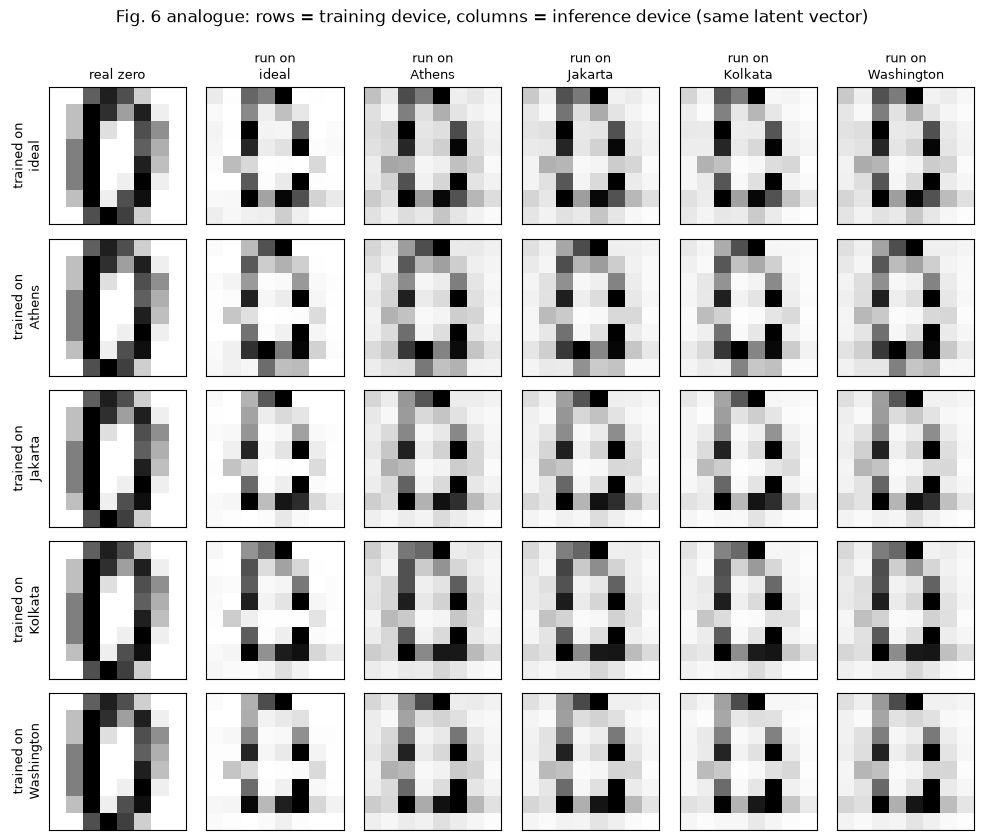

In [16]:
rows_tr = ["ideal", "Athens", "Jakarta", "Kolkata", "Washington"]
cols_inf = ["ideal", "Athens", "Jakarta", "Kolkata", "Washington"]
zfix = torch.rand(1, N_Q, generator=torch.Generator().manual_seed(5), dtype=torch.float64) * (np.pi / 2)
fig, axs = plt.subplots(len(rows_tr), len(cols_inf) + 1, figsize=(10, 8.4))
for i, tr in enumerate(rows_tr):
    axs[i, 0].imshow(real[3].reshape(8, 8).numpy(), cmap="gray_r", vmin=0, vmax=1); axs[i, 0].set_ylabel(f"trained on\n{tr}", fontsize=9)
    for j, inf in enumerate(cols_inf):
        with torch.no_grad():
            im = patches_to_images(MODELS[(s0, (tr,))]["theta"], zfix, HW[inf]).reshape(8, 8).numpy()
        axs[i, j + 1].imshow(im, cmap="gray_r", vmin=0, vmax=1)
        if i == 0: axs[i, j + 1].set_title(f"run on\n{inf}", fontsize=9)
for a in axs.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
axs[0, 0].set_title("real zero", fontsize=9)
plt.suptitle("Fig. 6 analogue: rows = training device, columns = inference device (same latent vector)", y=0.995); plt.tight_layout(); plt.show()

In [17]:
# ---------------------------------------------------------------- watermark-extraction CNN (paper Table III) and Frechet distance
class WatermarkCNN(nn.Module):
    """3 x (Conv 3x3 + ReLU + MaxPool 2x2) with 32/64/128 filters -> Dense 512 + ReLU -> Dense(#classes) (softmax in the loss)."""
    def __init__(self, n_classes, img=150):
        super().__init__()
        self.c1, self.c2, self.c3 = nn.Conv2d(1, 32, 3), nn.Conv2d(32, 64, 3), nn.Conv2d(64, 128, 3)
        s = img
        for _ in range(3):
            s = (s - 2) // 2
        self.flat = 128 * s * s
        self.fc1, self.fc2 = nn.Linear(self.flat, 512), nn.Linear(512, n_classes)
        self.img = img
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        x = F.max_pool2d(F.relu(self.c3(x)), 2)
        return self.fc2(F.relu(self.fc1(x.flatten(1))))

def upscale(X64, img):
    """(n,64) intensities in [0,1] -> (n,1,img,img) bilinear up-sampling (CHOICE: the paper only says 8x8 -> 150x150)."""
    x = torch.as_tensor(np.asarray(X64), dtype=torch.float32).reshape(-1, 1, 8, 8)
    return F.interpolate(x, size=(img, img), mode="bilinear", align_corners=False)

def fit_cnn(Xtr, ytr, Xva, yva, n_classes, img, epochs, seed, batch=64, lr=1e-3):
    torch.manual_seed(seed)
    m = WatermarkCNN(n_classes, img)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    xtr, xva = upscale(Xtr, img), upscale(Xva, img)
    ytr_t, yva_t = torch.as_tensor(ytr), torch.as_tensor(yva)
    g = torch.Generator().manual_seed(seed)
    hist = dict(loss=[], acc=[], val_loss=[], val_acc=[])
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(xtr), generator=g); tl = ta = 0
        for i in range(0, len(xtr), batch):
            b = perm[i:i + batch]
            opt.zero_grad(); out = m(xtr[b]); loss = F.cross_entropy(out, ytr_t[b]); loss.backward(); opt.step()
            tl += loss.item() * len(b); ta += (out.argmax(1) == ytr_t[b]).sum().item()
        m.eval()
        with torch.no_grad():
            ov = m(xva)
            hist["val_loss"].append(F.cross_entropy(ov, yva_t).item()); hist["val_acc"].append((ov.argmax(1) == yva_t).float().mean().item())
        hist["loss"].append(tl / len(xtr)); hist["acc"].append(ta / len(xtr))
    return m, hist

@torch.no_grad()
def predict_proba(m, X, bs=256):
    m.eval(); x = upscale(X, m.img)
    return torch.cat([F.softmax(m(x[i:i + bs]), 1) for i in range(0, len(x), bs)]).numpy()

def frechet(f1, f2):
    """Frechet distance between Gaussians fitted to two feature sets (the FID formula, with our own feature extractor)."""
    m1, m2 = f1.mean(0), f2.mean(0)
    c1, c2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    cs = linalg.sqrtm(c1 @ c2)
    cs = cs[0] if isinstance(cs, tuple) else cs        # older SciPy versions may return (sqrtm, err)
    return float(((m1 - m2) ** 2).sum() + np.trace(c1 + c2 - 2 * cs.real))

## 5. Image quality: FID-style distance and the multi-device overhead (paper Fig. 5 and Fig. 9)

The paper uses the Inception FID. Inception expects large colour photographs, and the paper does not say how 8x8 digits were fed to it,
so the absolute numbers cannot be reproduced. We use the **same formula** (Frechet distance between Gaussians fitted to feature vectors)
with a small digit classifier as the feature extractor ("FDD"); *relative* statements ("pairs are 7.4 % worse than single devices") are
comparable, absolute values are not. Real-vs-real and noise-vs-real reference values show the scale.

feature extractor (MLP 64-32-16-10) accuracy on held-out digits: 0.964


reference: real zeros vs real zeros = 3.112 | uniform noise vs real zeros = 153.071


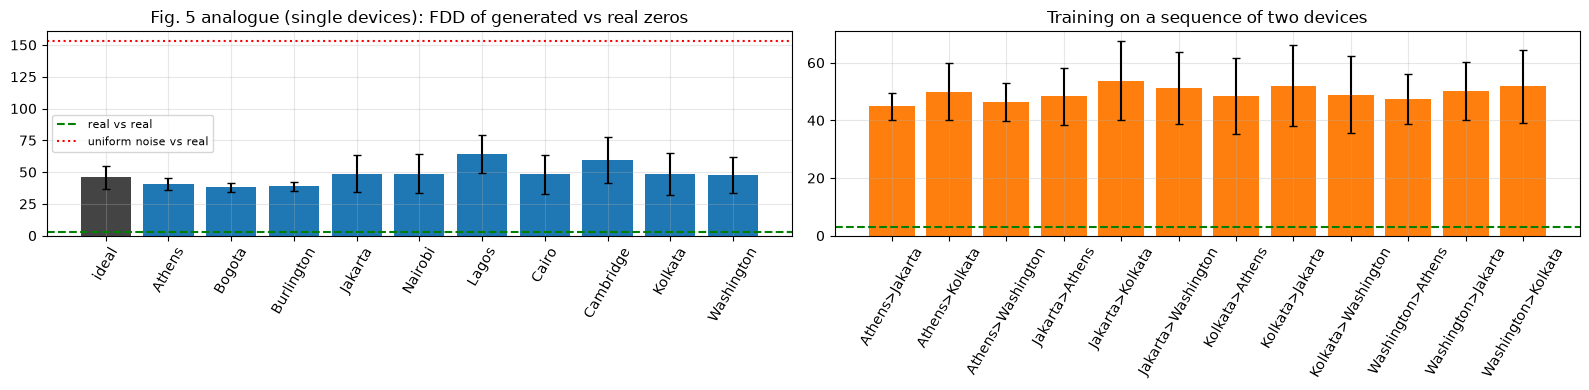

mean FDD change of two-device training vs single-device training: +7.8 % (paper: +7.4 %)
Athens>Jakarta: +3.1 % (paper: +18 %) | Jakarta>Athens: +8.7 % (paper: about 0 %)


In [18]:
mlp = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=400, random_state=SEED).fit(Xtr_d / 16.0, ytr_d)
print("feature extractor (MLP 64-32-16-10) accuracy on held-out digits: %.3f" % mlp.score(Xte_d / 16.0, yte_d))
def feats(X):
    h1 = np.maximum(0, np.asarray(X) @ mlp.coefs_[0] + mlp.intercepts_[0])
    return np.maximum(0, h1 @ mlp.coefs_[1] + mlp.intercepts_[1])
F_real = feats(real.numpy())
half = len(F_real) // 2
fdd_real_real = frechet(F_real[:half], F_real[half:])
fdd_noise = frechet(feats(np.random.default_rng(0).uniform(0, 1, (200, 64))), F_real)
N_FDD = max(10, 4 * N_IMG)
FDD = {}
for (sd, seq), m in MODELS.items():
    if seq[-1] in HW and sd in TRAIN_SEEDS + TEST_SEEDS:
        FDD[(sd, seq)] = frechet(feats(sample_images(m["theta"], HW[seq[-1]], N_FDD, 31337 + sd)), F_real)
print(f"reference: real zeros vs real zeros = {fdd_real_real:.3f} | uniform noise vs real zeros = {fdd_noise:.3f}")

def fdd_mean(seq, seeds=TRAIN_SEEDS + TEST_SEEDS):
    v = [FDD[(s, tuple(seq))] for s in seeds if (s, tuple(seq)) in FDD]
    return float(np.mean(v)), float(np.std(v))
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
labs = ["ideal"] + HW_SUITE
vals = [fdd_mean((h,)) for h in labs]
ax[0].bar(labs, [v[0] for v in vals], yerr=[v[1] for v in vals], color=["#444"] + ["C0"] * len(HW_SUITE), capsize=3)
ax[0].axhline(fdd_real_real, color="g", ls="--", label="real vs real"); ax[0].axhline(fdd_noise, color="r", ls=":", label="uniform noise vs real")
ax[0].set_title("Fig. 5 analogue (single devices): FDD of generated vs real zeros"); ax[0].tick_params(axis="x", rotation=60); ax[0].legend(fontsize=8)
labs2 = [f"{a}>{b}" for a, b in PAIRS]
vals2 = [fdd_mean(p) for p in PAIRS]
ax[1].bar(labs2, [v[0] for v in vals2], yerr=[v[1] for v in vals2], color="C1", capsize=3)
ax[1].axhline(fdd_real_real, color="g", ls="--"); ax[1].set_title("Training on a sequence of two devices"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

# overhead of a sequence relative to the mean of its two single-device models (same seed), paper: +7.4 % overall
inc = []
for sd in TRAIN_SEEDS + TEST_SEEDS:
    for (a, b) in PAIRS:
        base = 0.5 * (FDD[(sd, (a,))] + FDD[(sd, (b,))])
        inc.append(dict(seed=sd, pair=f"{a}>{b}", increase_pct=100 * (FDD[(sd, (a, b))] - base) / base))
inc = pd.DataFrame(inc)
OVERHEAD_ALL = inc.increase_pct.mean()
OVERHEAD_AJ = inc[inc.pair == "Athens>Jakarta"].increase_pct.mean()
OVERHEAD_JA = inc[inc.pair == "Jakarta>Athens"].increase_pct.mean()
print(f"mean FDD change of two-device training vs single-device training: {OVERHEAD_ALL:+.1f} % (paper: +7.4 %)")
print(f"Athens>Jakarta: {OVERHEAD_AJ:+.1f} % (paper: +18 %) | Jakarta>Athens: {OVERHEAD_JA:+.1f} % (paper: about 0 %)")

## 6. The watermark data set: train on device A, run on device B

For every trained qGAN we generate `N_IMG` images on **each of the 10 suite devices** (inference hardware), exactly like the paper
(100 images per run, label = *training* hardware). Three kinds of data are kept apart:

| Name | qGAN angles | Latent vectors | Inference device | Meaning |
|---|---|---|---|---|
| **train / val** | training seeds | fresh | the 10 suite devices | the classifier's data (random 80/20 split = the paper's own validation, Fig. 7) |
| **A: stolen copy** | *the same angles* as the owner's training seeds | fresh | held-out: noise-free + 3 unknown devices | an adversary copies the angles and runs them on hardware the classifier never saw |
| **B: independent re-training** | *unseen seeds* (re-trained from scratch) | fresh | the 10 suite devices | the paper's test construction ("re-train the qGAN with random seeds"); tells us whether the classifier reads the **hardware** or the **training run** |

In [19]:
import zlib
INF_SUITE = HW_SUITE
INF_HELD = ["ideal"] + HW_UNKNOWN
def seq_name(seq): return ">".join(seq)
def images_of(seed, seq, inf, tag):
    sd = zlib.crc32(f"{SEED}|{seed}|{seq}|{inf}|{tag}".encode()) % (2 ** 31)
    return sample_images(MODELS[(seed, tuple(seq))]["theta"], HW[inf], N_IMG, sd)
def build_set(seeds, seqs, infs, tag):
    X, y, inf_l, sd_l = [], [], [], []
    for s in seeds:
        for li, seq in enumerate(seqs):
            if (s, tuple(seq)) not in MODELS: continue
            for m in infs:
                im = images_of(s, seq, m, tag)
                X.append(im); y += [li] * len(im); inf_l += [m] * len(im); sd_l += [s] * len(im)
    return np.vstack(X), np.array(y), np.array(inf_l), np.array(sd_l)

SEQ1 = [(h,) for h in HW_SUITE]                                    # 10 labels
SEQ2 = [(h,) for h in HW_MULTI] + PAIRS                            # 4 + 12 = 16 labels
SEQ3 = [(a, b) for i, a in enumerate(HW_MULTI) for b in HW_MULTI[i + 1:]]   # 6 unique unordered pairs, one order each
X1, y1, inf1, sd1 = build_set(TRAIN_SEEDS, SEQ1, INF_SUITE, "train")
print("single-device classifier data:", X1.shape, "images,", len(SEQ1), "labels,", len(X1) // len(SEQ1), "per label (paper: 1000)")

single-device classifier data: (10000, 64) images, 10 labels, 1000 per label (paper: 1000)


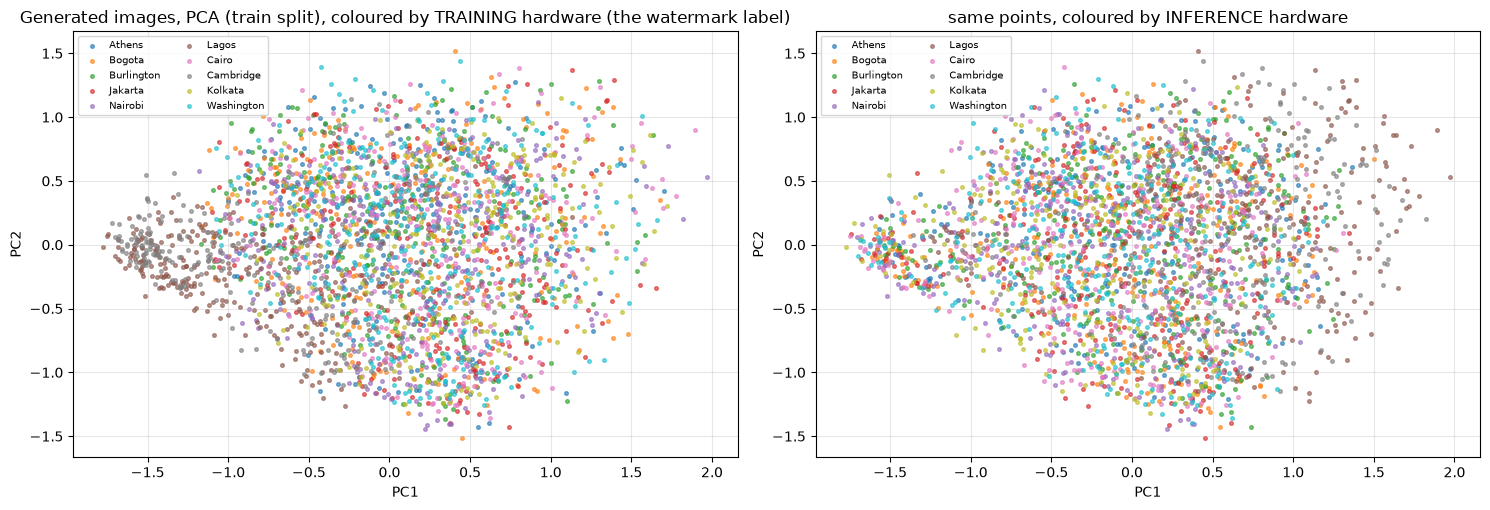

In [20]:
# labelled projection of the generated images: PCA fitted on the classifier's training split
tr_idx, va_idx = train_test_split(np.arange(len(X1)), test_size=0.2, stratify=y1, random_state=SEED)
pca_g = PCA(n_components=2, random_state=SEED).fit(X1[tr_idx])
P = pca_g.transform(X1[tr_idx])
sel = np.random.default_rng(0).choice(len(P), size=min(3000, len(P)), replace=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
cm10 = plt.get_cmap("tab10")
for k, h in enumerate(HW_SUITE):
    m = y1[tr_idx][sel] == k
    ax[0].scatter(P[sel][m, 0], P[sel][m, 1], s=7, color=cm10(k), alpha=0.6, label=h)
ax[0].set_title("Generated images, PCA (train split), coloured by TRAINING hardware (the watermark label)"); ax[0].legend(fontsize=7, ncol=2)
for k, h in enumerate(HW_SUITE):
    m = inf1[tr_idx][sel] == h
    ax[1].scatter(P[sel][m, 0], P[sel][m, 1], s=7, color=cm10(k), alpha=0.6, label=h)
ax[1].set_title("same points, coloured by INFERENCE hardware"); ax[1].legend(fontsize=7, ncol=2)
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

## 7. Watermark extraction for **single-device** training (paper Fig. 7.1/7.2 and Fig. 8.1)

### 7.1 The classifier (paper Table III)

The classifier class `WatermarkCNN` and its helpers were defined in the cell before section 5.

In [21]:
# parameter count of the architecture of Table III for the paper's 150x150 input - checks the table's own arithmetic
net150 = WatermarkCNN(10, 150)
npar = {n: p.numel() for n, p in net150.named_parameters()}
print({k: v for k, v in npar.items()})
print("flatten size at 150x150:", net150.flat, "(paper Table III: 36992)")
print("Dense-512 parameters computed from that flatten size:", net150.fc1.weight.numel() + net150.fc1.bias.numel(), "| paper Table III prints 21,234,176")
print("Output layer (10 classes):", net150.fc2.weight.numel() + net150.fc2.bias.numel(), "| paper: 5,130")
print("our IMG_SIZE =", IMG_SIZE, "-> total parameters:", sum(p.numel() for p in WatermarkCNN(10, IMG_SIZE).parameters()))

{'c1.weight': 288, 'c1.bias': 32, 'c2.weight': 18432, 'c2.bias': 64, 'c3.weight': 73728, 'c3.bias': 128, 'fc1.weight': 18939904, 'fc1.bias': 512, 'fc2.weight': 5120, 'fc2.bias': 10}
flatten size at 150x150: 36992 (paper Table III: 36992)
Dense-512 parameters computed from that flatten size: 18940416 | paper Table III prints 21,234,176
Output layer (10 classes): 5130 | paper: 5,130
our IMG_SIZE = 32 -> total parameters: 360458


CNN trained in 278 s | final train acc 0.7946 | final validation acc (paper protocol) 0.7420


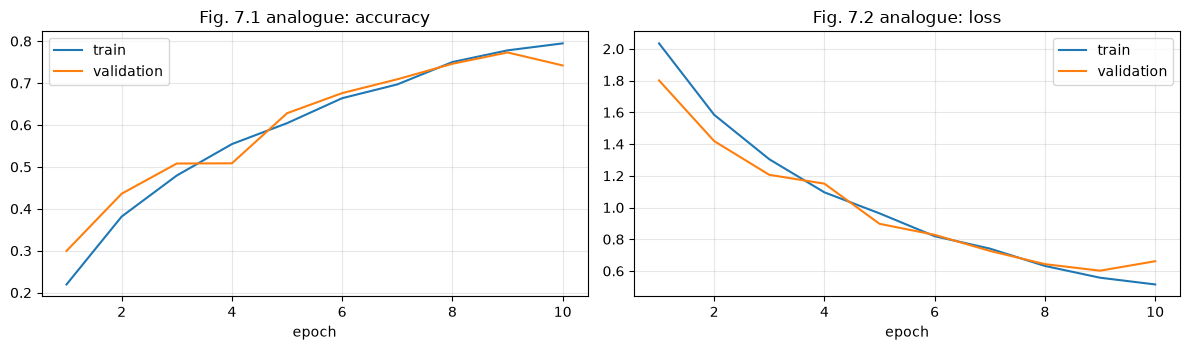

In [22]:
t0 = time.time()
cnn1, h1 = fit_cnn(X1[tr_idx], y1[tr_idx], X1[va_idx], y1[va_idx], len(SEQ1), IMG_SIZE, CLS_EPOCHS, SEED, batch=CLS_BATCH)
t_cnn1 = time.time() - t0
print(f"CNN trained in {t_cnn1:.0f} s | final train acc {h1['acc'][-1]:.4f} | final validation acc (paper protocol) {h1['val_acc'][-1]:.4f}")
ep = np.arange(1, CLS_EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(ep, h1["acc"], label="train"); ax[0].plot(ep, h1["val_acc"], label="validation"); ax[0].set_title("Fig. 7.1 analogue: accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, h1["loss"], label="train"); ax[1].plot(ep, h1["val_loss"], label="validation"); ax[1].set_title("Fig. 7.2 analogue: loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

### 7.2 Three ways to test it - and the classical baselines

Random forest and RBF-SVM are trained on **exactly the same 64 pixel intensities** (the CNN's up-scaling adds no information).

In [23]:
XA1, yA1, infA1, sdA1 = build_set(TRAIN_SEEDS, SEQ1, INF_HELD, "stolen")      # A: same angles, held-out inference devices
XB1, yB1, infB1, sdB1 = build_set(TEST_SEEDS, SEQ1, INF_SUITE, "retrain")      # B: unseen seeds
t0 = time.time(); rf1 = RandomForestClassifier(300, random_state=SEED, n_jobs=1).fit(X1[tr_idx], y1[tr_idx]); t_rf1 = time.time() - t0
t0 = time.time(); sv1 = SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED).fit(X1[tr_idx], y1[tr_idx]); t_sv1 = time.time() - t0
acc = lambda y, p: float((y == p).mean())
P_A1, P_B1 = predict_proba(cnn1, XA1), predict_proba(cnn1, XB1)
res1 = pd.DataFrame({
    "validation (paper protocol: random 20 % of the same trainings)": [h1["val_acc"][-1], rf1.score(X1[va_idx], y1[va_idx]), sv1.score(X1[va_idx], y1[va_idx])],
    "A: stolen angles, held-out inference devices": [acc(yA1, P_A1.argmax(1)), rf1.score(XA1, yA1), sv1.score(XA1, yA1)],
    "B: independent re-training (unseen seeds)": [acc(yB1, P_B1.argmax(1)), rf1.score(XB1, yB1), sv1.score(XB1, yB1)],
}, index=["CNN (Table III)", "RandomForest (64 px)", "SVC rbf (64 px)"]).round(4)
display(res1)
print("chance level for 10 labels = 0.10 | train time: CNN %.0f s, RF %.0f s, SVC %.0f s" % (t_cnn1, t_rf1, t_sv1))

,validation (paper protocol: random 20 % of the same trainings),"A: stolen angles, held-out inference devices",B: independent re-training (unseen seeds)
CNN (Table III),0.742,0.7098,0.2036
RandomForest (64 px),0.637,0.5468,0.1758
SVC rbf (64 px),0.977,0.9752,0.2236


chance level for 10 labels = 0.10 | train time: CNN 278 s, RF 48 s, SVC 7 s


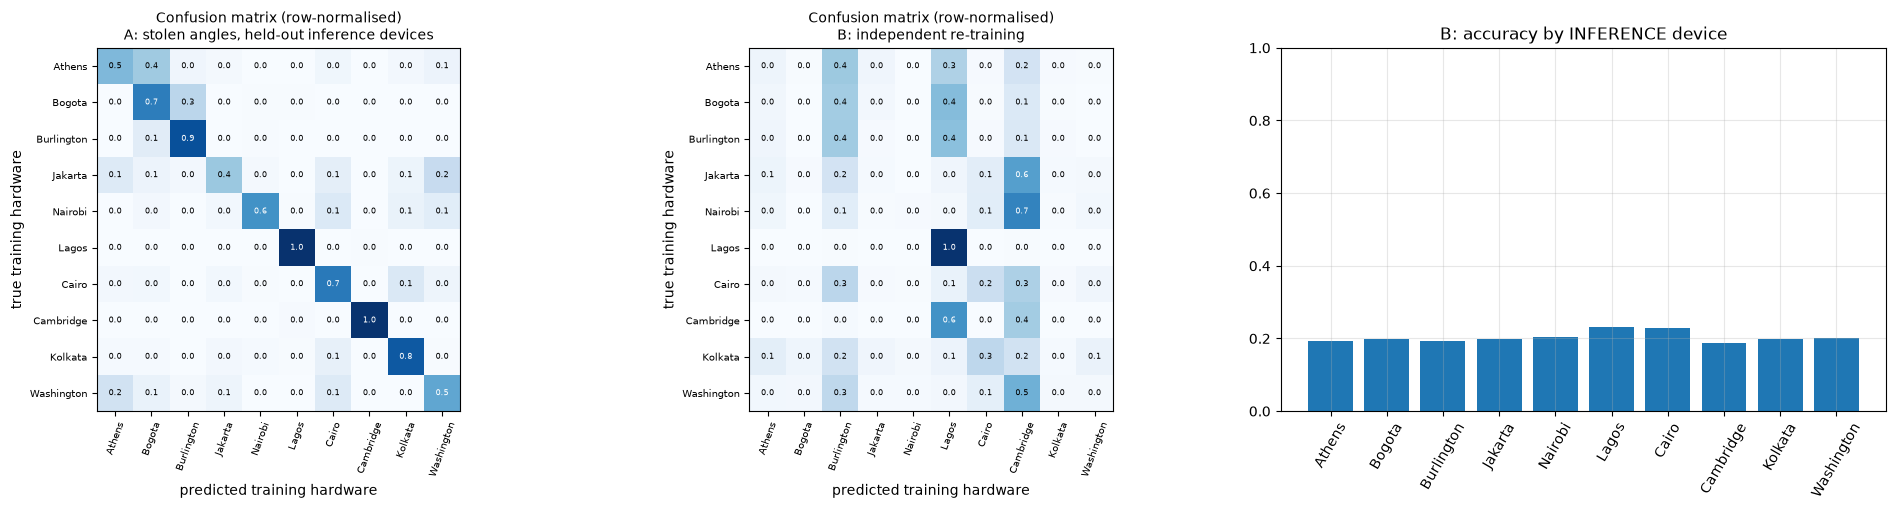

A: accuracy by held-out inference device: {'ideal': 0.667, 'Casablanca': 0.756, 'Almaden': 0.74, 'Essex': 0.676}


In [24]:
from sklearn.metrics import confusion_matrix
fig, ax = plt.subplots(1, 3, figsize=(20, 5.2))
for a, (y, p, ttl) in zip(ax[:2], [(yA1, P_A1.argmax(1), "A: stolen angles, held-out inference devices"), (yB1, P_B1.argmax(1), "B: independent re-training")]):
    cmx = confusion_matrix(y, p, labels=range(len(SEQ1)), normalize="true")
    im = a.imshow(cmx, cmap="Blues", vmin=0, vmax=1); a.set_title("Confusion matrix (row-normalised)\n" + ttl, fontsize=10)
    a.set_xticks(range(len(SEQ1))); a.set_xticklabels(HW_SUITE, rotation=70, fontsize=7); a.set_yticks(range(len(SEQ1))); a.set_yticklabels(HW_SUITE, fontsize=7)
    a.set_xlabel("predicted training hardware"); a.set_ylabel("true training hardware"); a.grid(False)
    for i in range(len(SEQ1)):
        for j in range(len(SEQ1)):
            a.text(j, i, f"{cmx[i, j]:.1f}", ha="center", va="center", fontsize=6, color="w" if cmx[i, j] > 0.5 else "k")
accs_inf = {m: acc(yB1[infB1 == m], P_B1.argmax(1)[infB1 == m]) for m in INF_SUITE}
ax[2].bar(list(accs_inf), list(accs_inf.values())); ax[2].set_title("B: accuracy by INFERENCE device"); ax[2].tick_params(axis="x", rotation=60); ax[2].set_ylim(0, 1)
plt.tight_layout(); plt.show()
accA_inf = pd.Series({m: acc(yA1[infA1 == m], P_A1.argmax(1)[infA1 == m]) for m in INF_HELD}).round(3)
print("A: accuracy by held-out inference device:", accA_inf.to_dict())

### 7.3 Ownership validation: threshold `M`, known and unknown hardware (paper Fig. 8.1)

The classifier only knows the 10 suite devices; an image from an *unknown* device will still be assigned to one of them, so the
paper introduces a threshold `M` = mean probability the classifier gives to the correct hardware on known test images.
A claim "this model was trained on `h`" is accepted if the predicted hardware is `h` **and** its probability is at least `M`.
Known devices (test): Washington and Cambridge; unknown: Casablanca, Almaden, Essex (plus the noise-free simulator as a control).

threshold M (single devices): protocol A = 0.7505 | protocol B = 0.1910   (paper: 0.9999)
Protocol A (same runs, other hardware for the unknown devices):


,kind,mean top probability,claim accepted (pred==h and p>=M),falsely accepted (p>=M)
Washington,known,0.6562,0.304,NaN
Cambridge,known,0.9917,0.985,NaN
Casablanca,unknown,0.729,NaN,0.501
Almaden,unknown,0.8348,NaN,0.723
Essex,unknown,0.8236,NaN,0.689
ideal,unknown,0.7509,NaN,0.562


Protocol B (unseen runs):


,kind,mean top probability,claim accepted (pred==h and p>=M),falsely accepted (p>=M)
Washington,known,0.881,0.028,NaN
Cambridge,known,0.9747,0.358,NaN
Casablanca,unknown,0.887,NaN,1.0
Almaden,unknown,0.9096,NaN,1.0
Essex,unknown,0.9673,NaN,1.0
ideal,unknown,0.7992,NaN,1.0


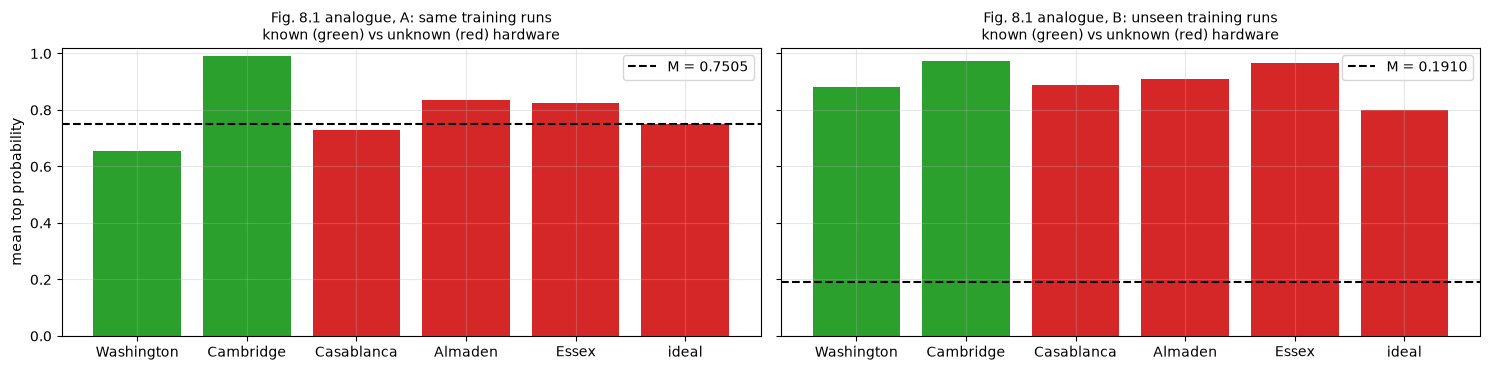

stolen copy of the Washington/Cambridge models run on held-out devices: mean p(true) = 0.7299, accepted with p>=M_A: 0.636


In [25]:
def ownership(proba_fn, SEQS, known_names, unknown_seqs, seeds, tag, M=None):
    """Returns dict with M, per-group mean top probability, acceptance rates."""
    name_to_idx = {seq_name(s): i for i, s in enumerate(SEQS)}
    Xk, yk, _, _ = build_set(seeds, [SEQS[name_to_idx[k]] for k in known_names], INF_SUITE, tag)
    pk = proba_fn(Xk)
    p_true = pk[np.arange(len(yk)), np.array([name_to_idx[known_names[i]] for i in yk])]
    M = float(p_true.mean()) if M is None else M
    out = dict(M=M, groups={}, name_to_idx=name_to_idx)
    for gi, k in enumerate(known_names):
        m = yk == gi
        pred = pk[m].argmax(1); tgt = name_to_idx[k]
        out["groups"][k] = dict(kind="known", mean_p_top=float(pk[m].max(1).mean()), mean_p_true=float(p_true[m].mean()),
                                accepted=float(((pred == tgt) & (pk[m][:, tgt] >= M)).mean()), p_true=p_true[m])
    for u in unknown_seqs:
        Xu, yu, _, _ = build_set(seeds, [u], INF_SUITE, tag + "-unk")
        pu = proba_fn(Xu)
        out["groups"][seq_name(u)] = dict(kind="unknown", mean_p_top=float(pu.max(1).mean()), accepted=float((pu.max(1) >= M).mean()), p_top=pu.max(1),
                                          predicted=pd.Series(pu.argmax(1)).map({v: k for k, v in name_to_idx.items()}).value_counts().head(3).to_dict())
    return out

UNK_SEQS = [(h,) for h in HW_UNKNOWN] + [("ideal",)]
fn1 = lambda X: predict_proba(cnn1, X)
# Protocol A: the owner's own training runs (same seeds, same initial angles and data stream; fresh latent vectors); the "unknown" devices were
#             trained with the same seeds. Protocol B: unseen seeds, i.e. the paper's "re-train with random seed values" test set.
own1 = ownership(fn1, SEQ1, KNOWN_SINGLE_TEST, UNK_SEQS, TRAIN_SEEDS, "own1A"); M1 = own1["M"]
own1B = ownership(fn1, SEQ1, KNOWN_SINGLE_TEST, UNK_SEQS, TEST_SEEDS, "own1B"); M1B = own1B["M"]
print(f"threshold M (single devices): protocol A = {M1:.4f} | protocol B = {M1B:.4f}   (paper: 0.9999)")
def own_table(o):
    return pd.DataFrame({k: {"kind": g["kind"], "mean top probability": round(g["mean_p_top"], 4), "claim accepted (pred==h and p>=M)" if g["kind"] == "known" else "falsely accepted (p>=M)": round(g["accepted"], 4)} for k, g in o["groups"].items()}).T
print("Protocol A (same runs, other hardware for the unknown devices):"); display(own_table(own1))
print("Protocol B (unseen runs):"); display(own_table(own1B))
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for a, o, ttl in zip(ax, [own1, own1B], ["A: same training runs", "B: unseen training runs"]):
    names_ = list(o["groups"]); vals_ = [o["groups"][k]["mean_p_top"] for k in names_]
    a.bar(names_, vals_, color=["C2" if o["groups"][k]["kind"] == "known" else "C3" for k in names_]); a.axhline(o["M"], color="k", ls="--", label=f"M = {o['M']:.4f}")
    a.set_ylim(0, 1.02); a.set_title("Fig. 8.1 analogue, " + ttl + "\nknown (green) vs unknown (red) hardware", fontsize=10); a.legend()
ax[0].set_ylabel("mean top probability"); plt.tight_layout(); plt.show()
# stolen copies (A): do the owner's own angles pass the same threshold on held-out inference devices?
pA_true = P_A1[np.arange(len(yA1)), yA1]
stolen_known = np.isin(yA1, [SEQ1.index((k,)) for k in KNOWN_SINGLE_TEST])
print("stolen copy of the Washington/Cambridge models run on held-out devices: mean p(true) = %.4f, accepted with p>=M_A: %.3f" % (
    pA_true[stolen_known].mean(), ((P_A1.argmax(1) == yA1) & (pA_true >= M1))[stolen_known].mean()))

## 8. Watermark extraction for **multi-device** training (paper Fig. 7.3/7.4 and Fig. 8.2)

16 labels: the 4 single devices {Athens, Jakarta, Kolkata, Washington} and their 12 ordered pairs (`h1>h2`: first half of the training on
`h1`, second half on `h2`). The paper reports about 90 % accuracy and `M` about 0.9.

multi-device classifier data: (16000, 64) | 16 labels, 1000 images per label (paper: 1000)


CNN trained in 314 s | train acc 0.6515 | validation acc (paper protocol) 0.6175


,validation (paper protocol),"A: stolen angles, held-out inference devices",B: independent re-training (unseen seeds)
CNN (Table III),0.6175,0.5923,0.0930
RandomForest (64 px),0.4253,0.3875,0.0756
SVC rbf (64 px),0.9300,0.9259,0.0994


chance level for 16 labels = 0.0625


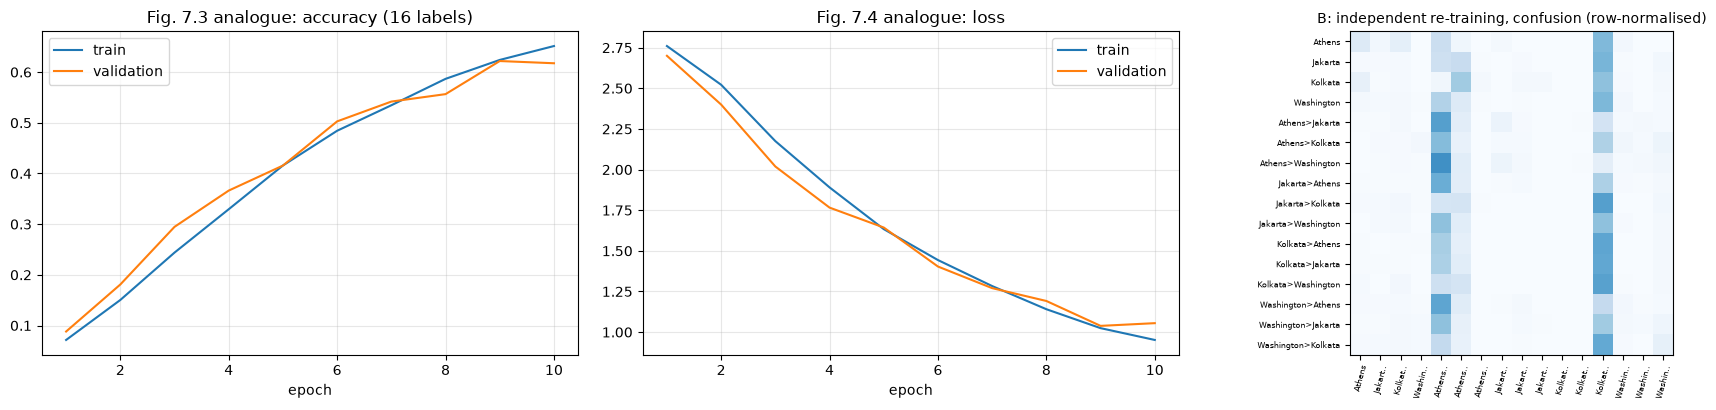

In [26]:
X2, y2, inf2, sd2 = build_set(TRAIN_SEEDS, SEQ2, INF_SUITE, "train2")
print("multi-device classifier data:", X2.shape, "|", len(SEQ2), "labels,", len(X2) // len(SEQ2), "images per label (paper: 1000)")
tr2, va2 = train_test_split(np.arange(len(X2)), test_size=0.2, stratify=y2, random_state=SEED)
t0 = time.time()
cnn2, h2 = fit_cnn(X2[tr2], y2[tr2], X2[va2], y2[va2], len(SEQ2), IMG_SIZE, CLS_EPOCHS, SEED, batch=CLS_BATCH)
print(f"CNN trained in {time.time() - t0:.0f} s | train acc {h2['acc'][-1]:.4f} | validation acc (paper protocol) {h2['val_acc'][-1]:.4f}")
XA2, yA2, infA2, _ = build_set(TRAIN_SEEDS, SEQ2, INF_HELD, "stolen2")
XB2, yB2, infB2, _ = build_set(TEST_SEEDS, SEQ2, INF_SUITE, "retrain2")
rf2 = RandomForestClassifier(300, random_state=SEED, n_jobs=1).fit(X2[tr2], y2[tr2])
sv2 = SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED).fit(X2[tr2], y2[tr2])
P_A2, P_B2 = predict_proba(cnn2, XA2), predict_proba(cnn2, XB2)
res2 = pd.DataFrame({
    "validation (paper protocol)": [h2["val_acc"][-1], rf2.score(X2[va2], y2[va2]), sv2.score(X2[va2], y2[va2])],
    "A: stolen angles, held-out inference devices": [acc(yA2, P_A2.argmax(1)), rf2.score(XA2, yA2), sv2.score(XA2, yA2)],
    "B: independent re-training (unseen seeds)": [acc(yB2, P_B2.argmax(1)), rf2.score(XB2, yB2), sv2.score(XB2, yB2)],
}, index=["CNN (Table III)", "RandomForest (64 px)", "SVC rbf (64 px)"]).round(4)
display(res2)
print("chance level for 16 labels = 0.0625")
ep = np.arange(1, CLS_EPOCHS + 1)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
ax[0].plot(ep, h2["acc"], label="train"); ax[0].plot(ep, h2["val_acc"], label="validation"); ax[0].set_title("Fig. 7.3 analogue: accuracy (16 labels)"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(ep, h2["loss"], label="train"); ax[1].plot(ep, h2["val_loss"], label="validation"); ax[1].set_title("Fig. 7.4 analogue: loss"); ax[1].legend(); ax[1].set_xlabel("epoch")
cmx = confusion_matrix(yB2, P_B2.argmax(1), labels=range(len(SEQ2)), normalize="true")
ax[2].imshow(cmx, cmap="Blues", vmin=0, vmax=1); ax[2].set_title("B: independent re-training, confusion (row-normalised)", fontsize=10); ax[2].grid(False)
ax[2].set_xticks(range(len(SEQ2))); ax[2].set_xticklabels([seq_name(s)[:6] + (".." if len(seq_name(s)) > 6 else "") for s in SEQ2], rotation=75, fontsize=6)
ax[2].set_yticks(range(len(SEQ2))); ax[2].set_yticklabels([seq_name(s) for s in SEQ2], fontsize=6)
plt.tight_layout(); plt.show()

threshold M (multiple devices): protocol A = 0.5028 | protocol B = 0.0280   (paper: about 0.9)
Protocol A:


,kind,mean top probability,claim accepted (pred==h and p>=M),falsely accepted (p>=M)
Athens>Kolkata,known,0.636,0.543,NaN
Jakarta>Athens,known,0.5789,0.466,NaN
Casablanca,unknown,0.6358,NaN,0.724
Almaden,unknown,0.7632,NaN,0.878
Essex,unknown,0.7699,NaN,0.857
ideal,unknown,0.741,NaN,0.815


Protocol B:


,kind,mean top probability,claim accepted (pred==h and p>=M),falsely accepted (p>=M)
Athens>Kolkata,known,0.8635,0.056,NaN
Jakarta>Athens,known,0.8824,0.0,NaN
Casablanca,unknown,0.8882,NaN,1.0
Almaden,unknown,0.9227,NaN,1.0
Essex,unknown,0.9372,NaN,1.0
ideal,unknown,0.787,NaN,1.0


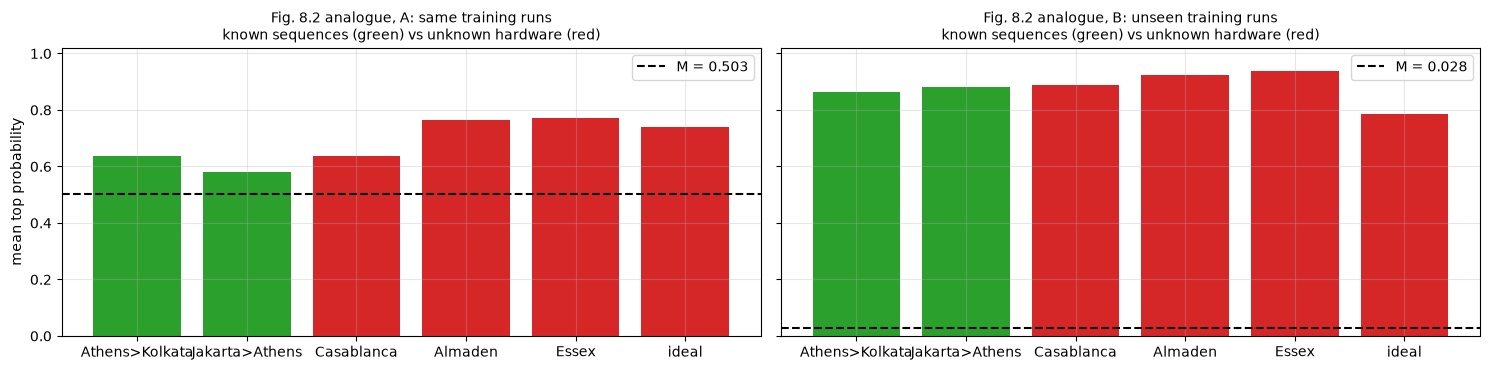

In [27]:
KNOWN_MULTI = ["Athens>Kolkata", "Jakarta>Athens"]
fn2 = lambda X: predict_proba(cnn2, X)
own2 = ownership(fn2, SEQ2, KNOWN_MULTI, UNK_SEQS, TRAIN_SEEDS, "own2A"); M2 = own2["M"]
own2B = ownership(fn2, SEQ2, KNOWN_MULTI, UNK_SEQS, TEST_SEEDS, "own2B"); M2B = own2B["M"]
print(f"threshold M (multiple devices): protocol A = {M2:.4f} | protocol B = {M2B:.4f}   (paper: about 0.9)")
print("Protocol A:"); display(own_table(own2))
print("Protocol B:"); display(own_table(own2B))
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for a, o, ttl in zip(ax, [own2, own2B], ["A: same training runs", "B: unseen training runs"]):
    names_ = list(o["groups"]); vals_ = [o["groups"][k]["mean_p_top"] for k in names_]
    a.bar(names_, vals_, color=["C2" if o["groups"][k]["kind"] == "known" else "C3" for k in names_]); a.axhline(o["M"], color="k", ls="--", label=f"M = {o['M']:.3f}")
    a.set_ylim(0, 1.02); a.set_title("Fig. 8.2 analogue, " + ttl + "\nknown sequences (green) vs unknown hardware (red)", fontsize=10); a.legend()
ax[0].set_ylabel("mean top probability"); plt.tight_layout(); plt.show()

### 8.1 Does the *order* of the devices matter? (paper Fig. 8.3)

6-label classifier on one order of each unordered pair. Test: the known sequences `Athens>Kolkata` and `Jakarta>Washington`, versus the
*reversed* sequences `Kolkata>Athens` and `Washington>Jakarta` that the classifier never saw. The paper reports `M` = 0.999 and a probability
"much less than M" for the reversed order.

In [28]:
X3, y3, _, _ = build_set(TRAIN_SEEDS, SEQ3, INF_SUITE, "train3")
tr3, va3 = train_test_split(np.arange(len(X3)), test_size=0.2, stratify=y3, random_state=SEED)
cnn3, h3 = fit_cnn(X3[tr3], y3[tr3], X3[va3], y3[va3], len(SEQ3), IMG_SIZE, CLS_EPOCHS, SEED, batch=CLS_BATCH)
print(f"order classifier: 6 labels | validation acc {h3['val_acc'][-1]:.4f} (paper: almost 100 %)")
fn3 = lambda X: predict_proba(cnn3, X)
KNOWN_ORD = [("Athens", "Kolkata"), ("Jakarta", "Washington")]
def order_test(seeds, tag):
    own = ownership(fn3, SEQ3, [seq_name(k) for k in KNOWN_ORD], [], seeds, tag)
    M, idx3, rows = own["M"], own["name_to_idx"], []
    for kn in KNOWN_ORD:
        rev = tuple(reversed(kn))
        Xr, _, _, _ = build_set(seeds, [rev], INF_SUITE, tag + "-rev")
        pr = fn3(Xr); c = idx3[seq_name(kn)]
        rows.append(dict(claimed=seq_name(kn), tested_images="reversed " + seq_name(rev), mean_p_claimed=pr[:, c].mean(), frac_p_claimed_ge_M=(pr[:, c] >= M).mean(), frac_argmax_is_claimed=(pr.argmax(1) == c).mean()))
        g = own["groups"][seq_name(kn)]
        rows.append(dict(claimed=seq_name(kn), tested_images="genuine " + seq_name(kn), mean_p_claimed=g["mean_p_true"], frac_p_claimed_ge_M=g["accepted"], frac_argmax_is_claimed=np.nan))
    return M, pd.DataFrame(rows).round(4)
M3, ORDER = order_test(TRAIN_SEEDS, "ordA")          # protocol A: the owner's own runs
M3B, ORDER_B = order_test(TEST_SEEDS, "ordB")        # protocol B: unseen runs
print(f"threshold M (order test): protocol A = {M3:.4f} | protocol B = {M3B:.4f}   (paper: 0.999)")
print("Protocol A:"); display(ORDER)
print("Protocol B:"); display(ORDER_B)

order classifier: 6 labels | validation acc 0.6708 (paper: almost 100 %)


threshold M (order test): protocol A = 0.5010 | protocol B = 0.0453   (paper: 0.999)
Protocol A:


,claimed,tested_images,mean_p_claimed,frac_p_claimed_ge_M,frac_argmax_is_claimed
0,Athens>Kolkata,reversed Kolkata>Athens,0.1093,0.037,0.110
1,Athens>Kolkata,genuine Athens>Kolkata,0.6114,0.687,NaN
2,Jakarta>Washington,reversed Washington>Jakarta,0.2993,0.132,0.307
3,Jakarta>Washington,genuine Jakarta>Washington,0.3906,0.232,NaN


Protocol B:


,claimed,tested_images,mean_p_claimed,frac_p_claimed_ge_M,frac_argmax_is_claimed
0,Athens>Kolkata,reversed Kolkata>Athens,0.1273,0.366,0.102
1,Athens>Kolkata,genuine Athens>Kolkata,0.0722,0.038,NaN
2,Jakarta>Washington,reversed Washington>Jakarta,0.0322,0.110,0.024
3,Jakarta>Washington,genuine Jakarta>Washington,0.0185,0.012,NaN


## 9. Can the thief erase the watermark by re-training? (paper Fig. 10)

The paper's tampering experiment: take a model trained on `Athens>Jakarta`, train it further for a few epochs on *different, unknown* hardware,
and see whether the classifier still recognises `Athens>Jakarta`. Our adversary knows the angles (white-box), has a fresh discriminator and
a noise model (Casablanca) the classifier has never seen. We track the mean probability of the original label over images generated on all 10 suite devices.

,tamper_epochs,mean_p_original_label,frac_classified_as_original
0,0,0.6319,0.72
1,10,0.4908,0.59
2,20,0.4328,0.51
3,30,0.3696,0.43
4,40,0.3537,0.46


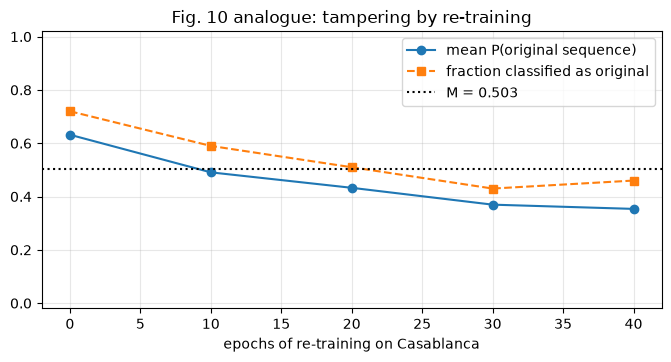

In [29]:
tm_seed = TRAIN_SEEDS[0]
lab = SEQ2.index(("Athens", "Jakarta"))
tamper_state = (MODELS[(tm_seed, ("Athens", "Jakarta"))]["theta"], init_gan(999)[1])
def wm_prob(theta, tag):
    X = np.vstack([sample_images(theta, HW[m], max(5, N_IMG // 5), zlib.crc32(f"tamper|{tag}|{m}".encode()) % (2 ** 31)) for m in INF_SUITE])
    p = predict_proba(cnn2, X)
    return float(p[:, lab].mean()), float((p.argmax(1) == lab).mean())
curve = [(0,) + wm_prob(tamper_state[0], 0)]
for e in range(TAMPER_EVERY, TAMPER_EPOCHS + 1, TAMPER_EVERY):
    tamper_state, _, _ = train_gan(tamper_state, HW["Casablanca"], real, TAMPER_EVERY, 5000 + e, batch=BATCH, lrG=LR_G, lrD=LR_D)
    curve.append((e,) + wm_prob(tamper_state[0], e))
curve = pd.DataFrame(curve, columns=["tamper_epochs", "mean_p_original_label", "frac_classified_as_original"]).round(4)
display(curve)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curve.tamper_epochs, curve.mean_p_original_label, "o-", label="mean P(original sequence)"); ax.plot(curve.tamper_epochs, curve.frac_classified_as_original, "s--", label="fraction classified as original")
ax.axhline(M2, color="k", ls=":", label=f"M = {M2:.3f}"); ax.set_xlabel("epochs of re-training on Casablanca"); ax.set_ylim(-0.02, 1.02); ax.legend(); ax.set_title("Fig. 10 analogue: tampering by re-training")
plt.show()

## 10. Uniqueness of the watermark (Section VI-A of the paper)

The paper states a collision probability of `0.1` for one device out of `n = 10`, "about 13 times lower" for a sequence of two devices, and
"about 1e-5" for a sequence of 5 out of 15 devices. This is pure arithmetic and can be checked exactly.

In [30]:
def collision(n, k):                       # paper formula: prod_{i=1..k} 1/(n-i)
    return float(np.prod([1.0 / (n - i) for i in range(1, k + 1)]))
def ordered(n, k):                         # number of ordered sequences of k distinct devices out of n
    return 1.0 / np.prod([n - i for i in range(k)])
tab = pd.DataFrame({
    "single device (n=10)": [1 / 10, collision(10, 1), ordered(10, 1)],
    "sequence of 2 (n=10)": [np.nan, collision(10, 2), ordered(10, 2)],
    "sequence of 5 (n=15)": [np.nan, collision(15, 5), ordered(15, 5)],
}, index=["paper statement", "paper formula prod 1/(n-i)", "exact ordered sequences 1/(n!/(n-k)!)"])
display(tab)
print("reduction single -> pair: paper says ~13x | paper formula gives %.1fx | exact ordered pairs give %.1fx" % (0.1 / collision(10, 2), 0.1 / ordered(10, 2)))

,single device (n=10),sequence of 2 (n=10),sequence of 5 (n=15)
paper statement,0.100000,NaN,NaN
paper formula prod 1/(n-i),0.111111,0.013889,0.000004
exact ordered sequences 1/(n!/(n-k)!),0.100000,0.011111,0.000003


reduction single -> pair: paper says ~13x | paper formula gives 7.2x | exact ordered pairs give 9.0x


## 11. Paper versus this notebook

Every claim of the paper that the notebook can test, side by side. Verdict rule (set in advance): accuracies "reproduced" within 2 points,
probabilities/thresholds within 0.02 (0.05 for the multi-device `M`), relative FID changes within 5 percentage points; otherwise
"not reached" (ours lower/worse) or "exceeded" (ours higher), with the gap. "cannot be checked" when the paper gives no usable number or the
required resource (real hardware, Inception FID, exact calibration snapshot) is not available.

**Reading the verdicts.** For the FID-overhead rows lower is better, so "exceeded" there would mean a *smaller* overhead than the paper's.


In [31]:
def vnum(nb, paper, tol, higher_is_better=True):
    if nb is None or (isinstance(nb, float) and np.isnan(nb)): return "cannot be checked"
    if abs(nb - paper) <= tol: return "reproduced"
    return ("exceeded" if (nb > paper) == higher_is_better else "not reached") + f" (gap {nb - paper:+.3f})"
def cell(df, r, c): return float(df.loc[r, c])

fa = lambda o: float(np.mean([g["accepted"] for k, g in o["groups"].items() if g["kind"] == "unknown" and k != "ideal"]))
fa1, fa1B, fa2, fa2B = fa(own1), fa(own1B), fa(own2), fa(own2B)
rev = ORDER[ORDER.tested_images.str.startswith("reversed")]; revB = ORDER_B[ORDER_B.tested_images.str.startswith("reversed")]
ordv = lambda r, M: "reproduced" if (r.mean_p_claimed.mean() < M - 0.1 and r.frac_p_claimed_ge_M.mean() < 0.1) else "not reached"
n_ok_ro = sum(ok_ro.values()); n_ok_x = sum(ok_x.values())
tamper_min = float(curve.mean_p_original_label.min()); tamper_final = float(curve.mean_p_original_label.iloc[-1])
c1, c2 = res1.columns[0], res1.columns[1]; c3 = res1.columns[2]
rows = [
 ("Table IV: readout error of the 10 devices (calibration snapshot)", "10 of 10 devices", f"{n_ok_ro} of 10 within 10 %", "reproduced" if n_ok_ro >= 9 else f"not reached ({n_ok_ro}/10)"),
 ("Table IV: Pauli-X (sx) error of the 10 devices", "10 of 10 devices", f"{n_ok_x} of 10 within 10 %", "reproduced" if n_ok_x >= 9 else f"not reached ({n_ok_x}/10)"),
 ("Table IV: thermal-relaxation column 'TR'", "0.019 - 0.041", "quantity undefined in the paper", "cannot be checked"),
 ("Fig. 1: hardware noise changes the learned angles", "visible drift vs ideal", f"mean |d theta| = {np.mean(list(drift_noise.values())):.3f} rad (seed-to-seed: {np.mean(list(drift_seed.values())):.3f} rad)",
  "reproduced (drift exists)" if np.mean(list(drift_noise.values())) > 0.01 else "not reached"),
 ("Single device: extraction accuracy, paper validation protocol (Fig. 7.1)", "100 %", f"{cell(res1, 'CNN (Table III)', c1):.3f}", vnum(cell(res1, 'CNN (Table III)', c1), 1.0, 0.02)),
 ("Single device: stolen angles, run on other hardware (Section I-B ii)", "100 %", f"{cell(res1, 'CNN (Table III)', c2):.3f}", vnum(cell(res1, 'CNN (Table III)', c2), 1.0, 0.02)),
 ("Single device: independent re-training as test data (Fig. 8.1 construction)", "about 100 % (prob ~1)", f"{cell(res1, 'CNN (Table III)', c3):.3f}", vnum(cell(res1, 'CNN (Table III)', c3), 1.0, 0.02)),
 ("Single device: threshold M, protocol A (owner's runs)", "0.9999", f"{M1:.4f}", vnum(M1, 0.9999, 0.02)),
 ("Single device: threshold M, protocol B (unseen runs; paper's construction)", "0.9999", f"{M1B:.4f}", vnum(M1B, 0.9999, 0.02)),
 ("Single device: unknown hardware gets p < M, protocol A", "all unknown below M", f"{100 * fa1:.1f} % of unknown images above M", "reproduced" if fa1 <= 0.02 else f"not reached ({100 * fa1:.1f} % falsely accepted)"),
 ("Single device: unknown hardware gets p < M, protocol B", "all unknown below M", f"{100 * fa1B:.1f} % of unknown images above M", "reproduced" if fa1B <= 0.02 else f"not reached ({100 * fa1B:.1f} % falsely accepted)"),
 ("Multi device (16 labels): extraction accuracy, paper protocol (Fig. 7.3)", "about 90 %", f"{cell(res2, 'CNN (Table III)', res2.columns[0]):.3f}", vnum(cell(res2, 'CNN (Table III)', res2.columns[0]), 0.90, 0.02)),
 ("Multi device: stolen angles, other hardware", "about 90 %", f"{cell(res2, 'CNN (Table III)', res2.columns[1]):.3f}", vnum(cell(res2, 'CNN (Table III)', res2.columns[1]), 0.90, 0.02)),
 ("Multi device: independent re-training", "about 90 %", f"{cell(res2, 'CNN (Table III)', res2.columns[2]):.3f}", vnum(cell(res2, 'CNN (Table III)', res2.columns[2]), 0.90, 0.02)),
 ("Multi device: threshold M, protocol A", "about 0.9", f"{M2:.3f}", vnum(M2, 0.9, 0.05)),
 ("Multi device: threshold M, protocol B", "about 0.9", f"{M2B:.3f}", vnum(M2B, 0.9, 0.05)),
 ("Multi device: unknown hardware gets p < M, protocol A", "all unknown below M", f"{100 * fa2:.1f} % of unknown images above M", "reproduced" if fa2 <= 0.02 else f"not reached ({100 * fa2:.1f} % falsely accepted)"),
 ("Multi device: unknown hardware gets p < M, protocol B", "all unknown below M", f"{100 * fa2B:.1f} % of unknown images above M", "reproduced" if fa2B <= 0.02 else f"not reached ({100 * fa2B:.1f} % falsely accepted)"),
 ("Order test: classifier accuracy (6 labels)", "almost 100 %", f"{h3['val_acc'][-1]:.3f}", vnum(h3["val_acc"][-1], 1.0, 0.02)),
 ("Order test: threshold M, protocol A", "0.999", f"{M3:.4f}", vnum(M3, 0.999, 0.02)),
 ("Order test: reversed sequence gets p << M, protocol A", "much less than M", f"mean p = {rev.mean_p_claimed.mean():.3f}, {100 * rev.frac_p_claimed_ge_M.mean():.1f} % above M", ordv(rev, M3)),
 ("Order test: reversed sequence gets p << M, protocol B", "much less than M", f"mean p = {revB.mean_p_claimed.mean():.3f}, {100 * revB.frac_p_claimed_ge_M.mean():.1f} % above M (M = {M3B:.3f})", ordv(revB, M3B)),
 ("FID overhead of two-device training, all pairs (FDD, relative)", "+7.4 %", f"{OVERHEAD_ALL:+.1f} %", vnum(OVERHEAD_ALL, 7.4, 5.0, higher_is_better=False)),
 ("FID overhead Athens>Jakarta", "+18 %", f"{OVERHEAD_AJ:+.1f} %", vnum(OVERHEAD_AJ, 18.0, 5.0, higher_is_better=False)),
 ("FID overhead Jakarta>Athens", "about 0 %", f"{OVERHEAD_JA:+.1f} %", vnum(OVERHEAD_JA, 0.0, 5.0, higher_is_better=False)),
 ("Absolute FID values (Fig. 5, 9)", "0.4 - 1.2 (Inception FID)", "FDD, different scale", "cannot be checked"),
 ("Tampering: P(original) stays above M during re-training (Fig. 10)", "> M for 100 epochs", f"min {tamper_min:.3f}, final {tamper_final:.3f} vs M = {M2:.3f}",
  "reproduced" if tamper_min >= M2 else f"not reached (min {tamper_min:.3f} < M)"),
 ("Table III: Dense-512 parameter count at 150x150 input", "21,234,176", f"{net150.fc1.weight.numel() + net150.fc1.bias.numel():,}", "not reproduced (table inconsistent with its own flatten size)"),
 ("Collision probability, single device (n=10)", "0.1", f"{collision(10, 1):.3f} (formula) / 0.100 (exact 1/n)", "reproduced (as 1/n)"),
 ("Collision reduction single -> pair", "about 13x", f"{0.1 / collision(10, 2):.1f}x (formula), {0.1 / ordered(10, 2):.1f}x (exact)", "not reproduced"),
 ("Collision probability, 5 of 15 devices", "about 1e-5", f"{collision(15, 5):.1e} (formula), {ordered(15, 5):.1e} (exact)", "order of magnitude only"),
 ("Real IBM hardware / qubit-count and coupling-map effects", "simulated fake backends only", "device-median noise, no routing", "cannot be checked"),
]
CMP = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 90, "display.width", 250)
display(CMP.style.set_properties(**{"text-align": "left"}))
nrep = CMP.verdict.str.startswith("reproduced").sum(); nnot = CMP.verdict.str.startswith("not").sum(); nex = CMP.verdict.str.startswith("exceeded").sum(); nch = CMP.verdict.str.startswith("cannot").sum()
print(f"verdicts: {nrep} reproduced | {nnot} not reached / not reproduced | {nex} exceeded | {nch} cannot be checked | other: {len(CMP) - nrep - nnot - nex - nch}")
print("total notebook run time: %.1f min (FAST_MODE=%s)" % ((time.time() - NB_T0) / 60, FAST_MODE))

,claim,paper,this notebook,verdict
0,Table IV: readout error of the 10 devices (calibration snapshot),10 of 10 devices,5 of 10 within 10 %,not reached (5/10)
1,Table IV: Pauli-X (sx) error of the 10 devices,10 of 10 devices,6 of 10 within 10 %,not reached (6/10)
2,Table IV: thermal-relaxation column 'TR',0.019 - 0.041,quantity undefined in the paper,cannot be checked
3,Fig. 1: hardware noise changes the learned angles,visible drift vs ideal,mean |d theta| = 0.136 rad (seed-to-seed: 0.540 rad),reproduced (drift exists)
4,"Single device: extraction accuracy, paper validation protocol (Fig. 7.1)",100 %,0.742,not reached (gap -0.258)
5,"Single device: stolen angles, run on other hardware (Section I-B ii)",100 %,0.710,not reached (gap -0.290)
6,Single device: independent re-training as test data (Fig. 8.1 construction),about 100 % (prob ~1),0.204,not reached (gap -0.796)
7,"Single device: threshold M, protocol A (owner's runs)",0.9999,0.7505,not reached (gap -0.249)
8,"Single device: threshold M, protocol B (unseen runs; paper's construction)",0.9999,0.1910,not reached (gap -0.809)
9,"Single device: unknown hardware gets p < M, protocol A",all unknown below M,63.8 % of unknown images above M,not reached (63.8 % falsely accepted)


verdicts: 4 reproduced | 23 not reached / not reproduced | 1 exceeded | 3 cannot be checked | other: 1
total notebook run time: 42.5 min (FAST_MODE=True)


## 12. Reading the paper critically

*(Numbers refer to the executed `FAST_MODE=True` run stored in this notebook: 250 training steps, 2 training seeds + 1 unseen seed, 50 images per model and inference device, 32x32 CNN input, 10 CNN epochs. The paper's 500 steps / 100 images / 150x150 input were not run; see the table in section 11.)*

**What reproduces.** (i) The mechanism is real in simulation: training the same qGAN (same initial angles, same data stream) on a noisy device instead of the noise-free simulator changes the learned angles by about 0.14 rad on average (0.05 rad on Kolkata up to 0.27 rad on Lagos), and devices differ from each other (Fig. 1 analogue, section 4.1). (ii) Within one training run the footprint is readable: an RBF-SVM on the 64 raw pixels names the training device of 98 % of the validation images of 10 devices (93 % of 16 sequences), so the information the paper wants to extract is present. (iii) The average quality cost of training on two devices (+7.8 % FDD) is close to the paper's +7.4 %. (iv) The order of the devices is partly visible: `Athens>Kolkata` gets probability 0.61 while the reversed `Kolkata>Athens` gets 0.11; for `Jakarta>Washington` the contrast is weaker (0.39 vs 0.30).

**What does not reproduce - and why it matters.**
1. *Run-to-run randomness is four times larger than the hardware footprint.* The same device trained with a different seed ends 0.54 rad away, versus 0.14 rad for the effect of noise. When the classifier is tested on **independently re-trained** qGANs (protocol B, which is how the paper says its test sets were built) accuracy collapses to 20 % for 10 devices (chance 10 %) and 9 % for 16 sequences (chance 6 %), for the CNN **and** for the SVM and random forest. What the classifier learns is mostly *which training run* an image comes from, not which hardware. The paper does not state how many independent trainings its classifier saw, so its 100 % / 90 % may be a within-run number.
2. *The 'stolen model' scenario (protocol A) works only because the copy is the owner's own model.* Running the same angles on other hardware keeps accuracy (CNN 71 %, SVM 98 %), but this is identification of a *specific trained model*, which needs no quantum noise at all (any two trainings differ, as point 1 shows). It is a legitimate fingerprint, just not evidence that the hardware is the watermark.
3. *The threshold `M` does not separate known from unknown hardware.* With the paper's definition (mean probability of the right label on known test images) `M` is 0.75 in protocol A and 0.19 in protocol B (paper 0.9999). Images from unknown devices receive top-probabilities as high as known ones (63.8 % of them exceed `M` in A, 100 % in B), because a softmax always puts its mass on some known class. The claim that unknown hardware falls below `M` is not supported here.
4. *Tampering is much easier than the paper reports.* Re-training the stolen angles for only 10 epochs on an unseen device drops the probability of the original label from 0.63 to 0.49, below `M = 0.50`, and to 0.35 after 40 epochs (paper: above `M` for 100 epochs).
5. *Pair-specific FID claims differ:* Athens>Jakarta +3 % (paper +18 %), Jakarta>Athens +9 % (paper about 0 %). With 3 seeds these per-pair numbers are noisy, so we do not read much into them.
6. *The paper's own arithmetic is inconsistent in places.* Table III prints 21,234,176 parameters for the 512-unit dense layer, but a flatten size of 36,992 gives 18,940,416; the collision probability for a pair of devices is 0.011-0.014, i.e. 7-9 times (not "about 13 times") lower than 0.1; for 5 of 15 devices it is 3-4e-6, not 1e-5.
7. *Methodological caveats of the paper itself:* the 8x8 to 150x150 up-scaling adds no information; the Inception FID of 8x8 digits is undefined; "TR" in Table IV is not defined; only digit 0 and fake backends were used; the ghost-watermark and removal arguments of Section VI are verbal, not tested.

**Caveats of this reproduction (read before quoting numbers).** Hardware noise is a device-median Kraus model derived from today's Qiskit snapshots (they match Table IV for only about half of the devices; qubit count and routing are not modelled, so device size cannot act as a signature); the CNN is an exact copy of Table III but is under-trained in `FAST_MODE` (validation 74 % while the SVM reaches 98 %, so the *CNN* numbers are lower bounds, not the information limit); the full-budget run (500 steps, 3+2 seeds, 100 images per run, 15 CNN epochs) was not executed because it takes several hours on this shared machine; no real IBM hardware, no shot noise. A fair conclusion is therefore: **the qualitative mechanism (noise leaves a measurable, order-dependent footprint in the angles) is confirmed; the quantitative claims (100 % / 90 % extraction, M = 0.9999, unknown-hardware rejection, robustness to tampering) are not reached here, and the central test of the claim - independent re-trainings - fails.**

## 13. Exercises

1. **Seed versus hardware.** Re-run section 7 with `TRAIN_SEEDS = [0, 1, 2, 3, 4]`. How do the *independent re-training* (B) accuracies change? What does that say about
   how many training runs an owner needs before the classifier reads the hardware instead of the run?
2. **Noise strength.** Pass `scale=3.0` to `build_noise` (three times the calibrated error) and repeat sections 4-8. Is the watermark stronger? How much does the image quality (section 5) suffer?
3. **Make the thief smarter.** In section 9 give the adversary the *same* noise model as the owner (re-train on Athens instead of Casablanca) or a noise-free simulator. Does the
   watermark survive, and what would that mean for the proof of ownership?
4. **A better detector.** Replace the CNN by a classifier on hand-made features (mean pixel intensity, the 16 patch maxima before normalisation) and compare with section 7.2.
   Are the 150x150 up-sampled pictures of the paper necessary at all?
5. **Ghost watermark.** Train an *independent* qGAN on a never-seen device and ask the owner's classifier whether it carries the owner's watermark. Which threshold `M`
   keeps the false-claim rate below 1 % while the detection rate stays above 90 %? (Use the ROC of `p_top` for known vs unknown images.)